# Russell 2000, S&P 500, Nasdaq-100: log-return recurrences

Yahoo Finance via `yfinance`: **^RUT**, **^GSPC**, **^NDX**. Monthly closing index levels , using all available common history and excluding the current incomplete month. Returns are **100 × log(Pₜ/Pₜ₋₁)**, in log-percentage points.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

## Fetch complete monthly index levels

In [2]:
TICKERS = {"RUSSELL2000": "^RUT", "SP500": "^GSPC", "NASDAQ100": "^NDX"}
series_cols = list(TICKERS)
# Yahoo end is exclusive. Do not use the current, unfinished monthly bar.
END_EXCLUSIVE = pd.Timestamp.now(tz="America/New_York").tz_localize(None).normalize().replace(day=1)

raw_series = []
for name, ticker in TICKERS.items():
    history = yf.Ticker(ticker).history(
        period="max", interval="1mo", end=END_EXCLUSIVE.date().isoformat(),
        auto_adjust=False, actions=False, raise_errors=True,
    )
    if history.empty or "Close" not in history:
        raise RuntimeError(f"No monthly closing prices returned for {ticker}")
    s = history["Close"].astype(float).rename(name)
    s.index = pd.DatetimeIndex(s.index).tz_localize(None).to_period("M").to_timestamp()
    s = s.loc[s.index < END_EXCLUSIVE].sort_index()
    duplicates = int(s.index.duplicated(keep="last").sum())
    s = s.loc[~s.index.duplicated(keep="last")]
    # Non-positive/non-finite prices cannot be logged; treat them as missing.
    s = s.where(np.isfinite(s) & (s > 0))
    if s.notna().sum() < 2:
        raise RuntimeError(f"Insufficient usable prices for {ticker}")
    print(f"{name:12s} {s.first_valid_index():%Y-%m} to {s.last_valid_index():%Y-%m}; "
          f"rows={len(s)}, missing/invalid={s.isna().sum()}, duplicate months removed={duplicates}")
    raw_series.append(s)
prices_raw = pd.concat(raw_series, axis=1).sort_index()
print("Download cutoff (exclusive):", END_EXCLUSIVE.date())

<cell In[2]>:8: DeprecationWarning: 'raise_errors' deprecated, do: yf.config.debug.hide_exceptions = False
  history = yf.Ticker(ticker).history(


RUSSELL2000  1987-09 to 2026-09; rows=469, missing/invalid=0, duplicate months removed=0


<cell In[2]>:8: DeprecationWarning: 'raise_errors' deprecated, do: yf.config.debug.hide_exceptions = False
  history = yf.Ticker(ticker).history(


SP500        1985-01 to 2026-09; rows=501, missing/invalid=0, duplicate months removed=0


<cell In[2]>:8: DeprecationWarning: 'raise_errors' deprecated, do: yf.config.debug.hide_exceptions = False
  history = yf.Ticker(ticker).history(


NASDAQ100    1985-10 to 2026-09; rows=492, missing/invalid=0, duplicate months removed=0
Download cutoff (exclusive): 2026-10-01


## Align and clean

Use the overlap between each index's first and last usable month; Restore the monthly grid inside that overlap. Interpolate **log prices** only across interior gaps (geometric interpolation in levels). 

Print every imputed price month; flag a return if either endpoint price was imputed.

In [3]:
common_start = max(s.first_valid_index() for s in raw_series)
common_end = min(s.last_valid_index() for s in raw_series)
if common_start >= common_end:
    raise ValueError("The indices have no usable common monthly window")
monthly_index = pd.date_range(common_start, common_end, freq="MS", name="month")
prices_monthly = prices_raw.reindex(monthly_index)
price_imputed = prices_monthly.isna()
prices_clean = np.exp(np.log(prices_monthly).interpolate(method="linear", limit_area="inside"))
assert prices_clean.index.is_unique and prices_clean.index.is_monotonic_increasing
assert np.isfinite(prices_clean.to_numpy()).all(), "Unfilled price gap"

for col in series_cols:
    dates = list(prices_clean.index[price_imputed[col]].date)
    print(f"{col}: {len(dates)} imputed price months", dates)
print(f"Common prices: {common_start:%Y-%m} to {common_end:%Y-%m}; n={len(prices_clean)}")

RUSSELL2000: 0 imputed price months []
SP500: 0 imputed price months []
NASDAQ100: 0 imputed price months []
Common prices: 1987-09 to 2026-09; n=469


In [4]:
# One-period monthly log returns; drop only the first, undefined return.
returns = (100 * np.log(prices_clean).diff()).iloc[1:]
return_imputed = (price_imputed | price_imputed.shift(1, fill_value=False)).loc[returns.index]
market = returns.copy()
market["IMPUTED"] = return_imputed.any(axis=1)
assert market.index.is_monotonic_increasing and market.index.is_unique
assert len(market.asfreq("MS")) == len(market), "Gap in monthly return index"
assert np.isfinite(market[series_cols].to_numpy()).all(), "Invalid log return"
print(f"Returns: {market.index.min():%Y-%m} to {market.index.max():%Y-%m}; n={len(market)}")
print("Returns affected by imputation:", list(market.index[market["IMPUTED"]].date))
market.head()

Returns: 1987-10 to 2026-09; n=468
Returns affected by imputation: []


,RUSSELL2000,SP500,NASDAQ100,IMPUTED
month,,,,
1987-10-01,-36.766620,-24.542803,-31.436849,False
1987-11-01,-5.706893,-8.921256,-9.020898,False
1987-12-01,7.516894,7.032936,13.056437,False
1988-01-01,3.924626,3.963627,1.826422,False
1988-02-01,8.315808,4.096669,8.148699,False


## Index levels, returns, and imputation

Red markers appear only where a price was imputed or a return uses an imputed price. If there are no gaps, these are ordinary index and return charts with no imputation legend. Extremes are reported on the log returns, as these are the inputs to the recurrence analysis.

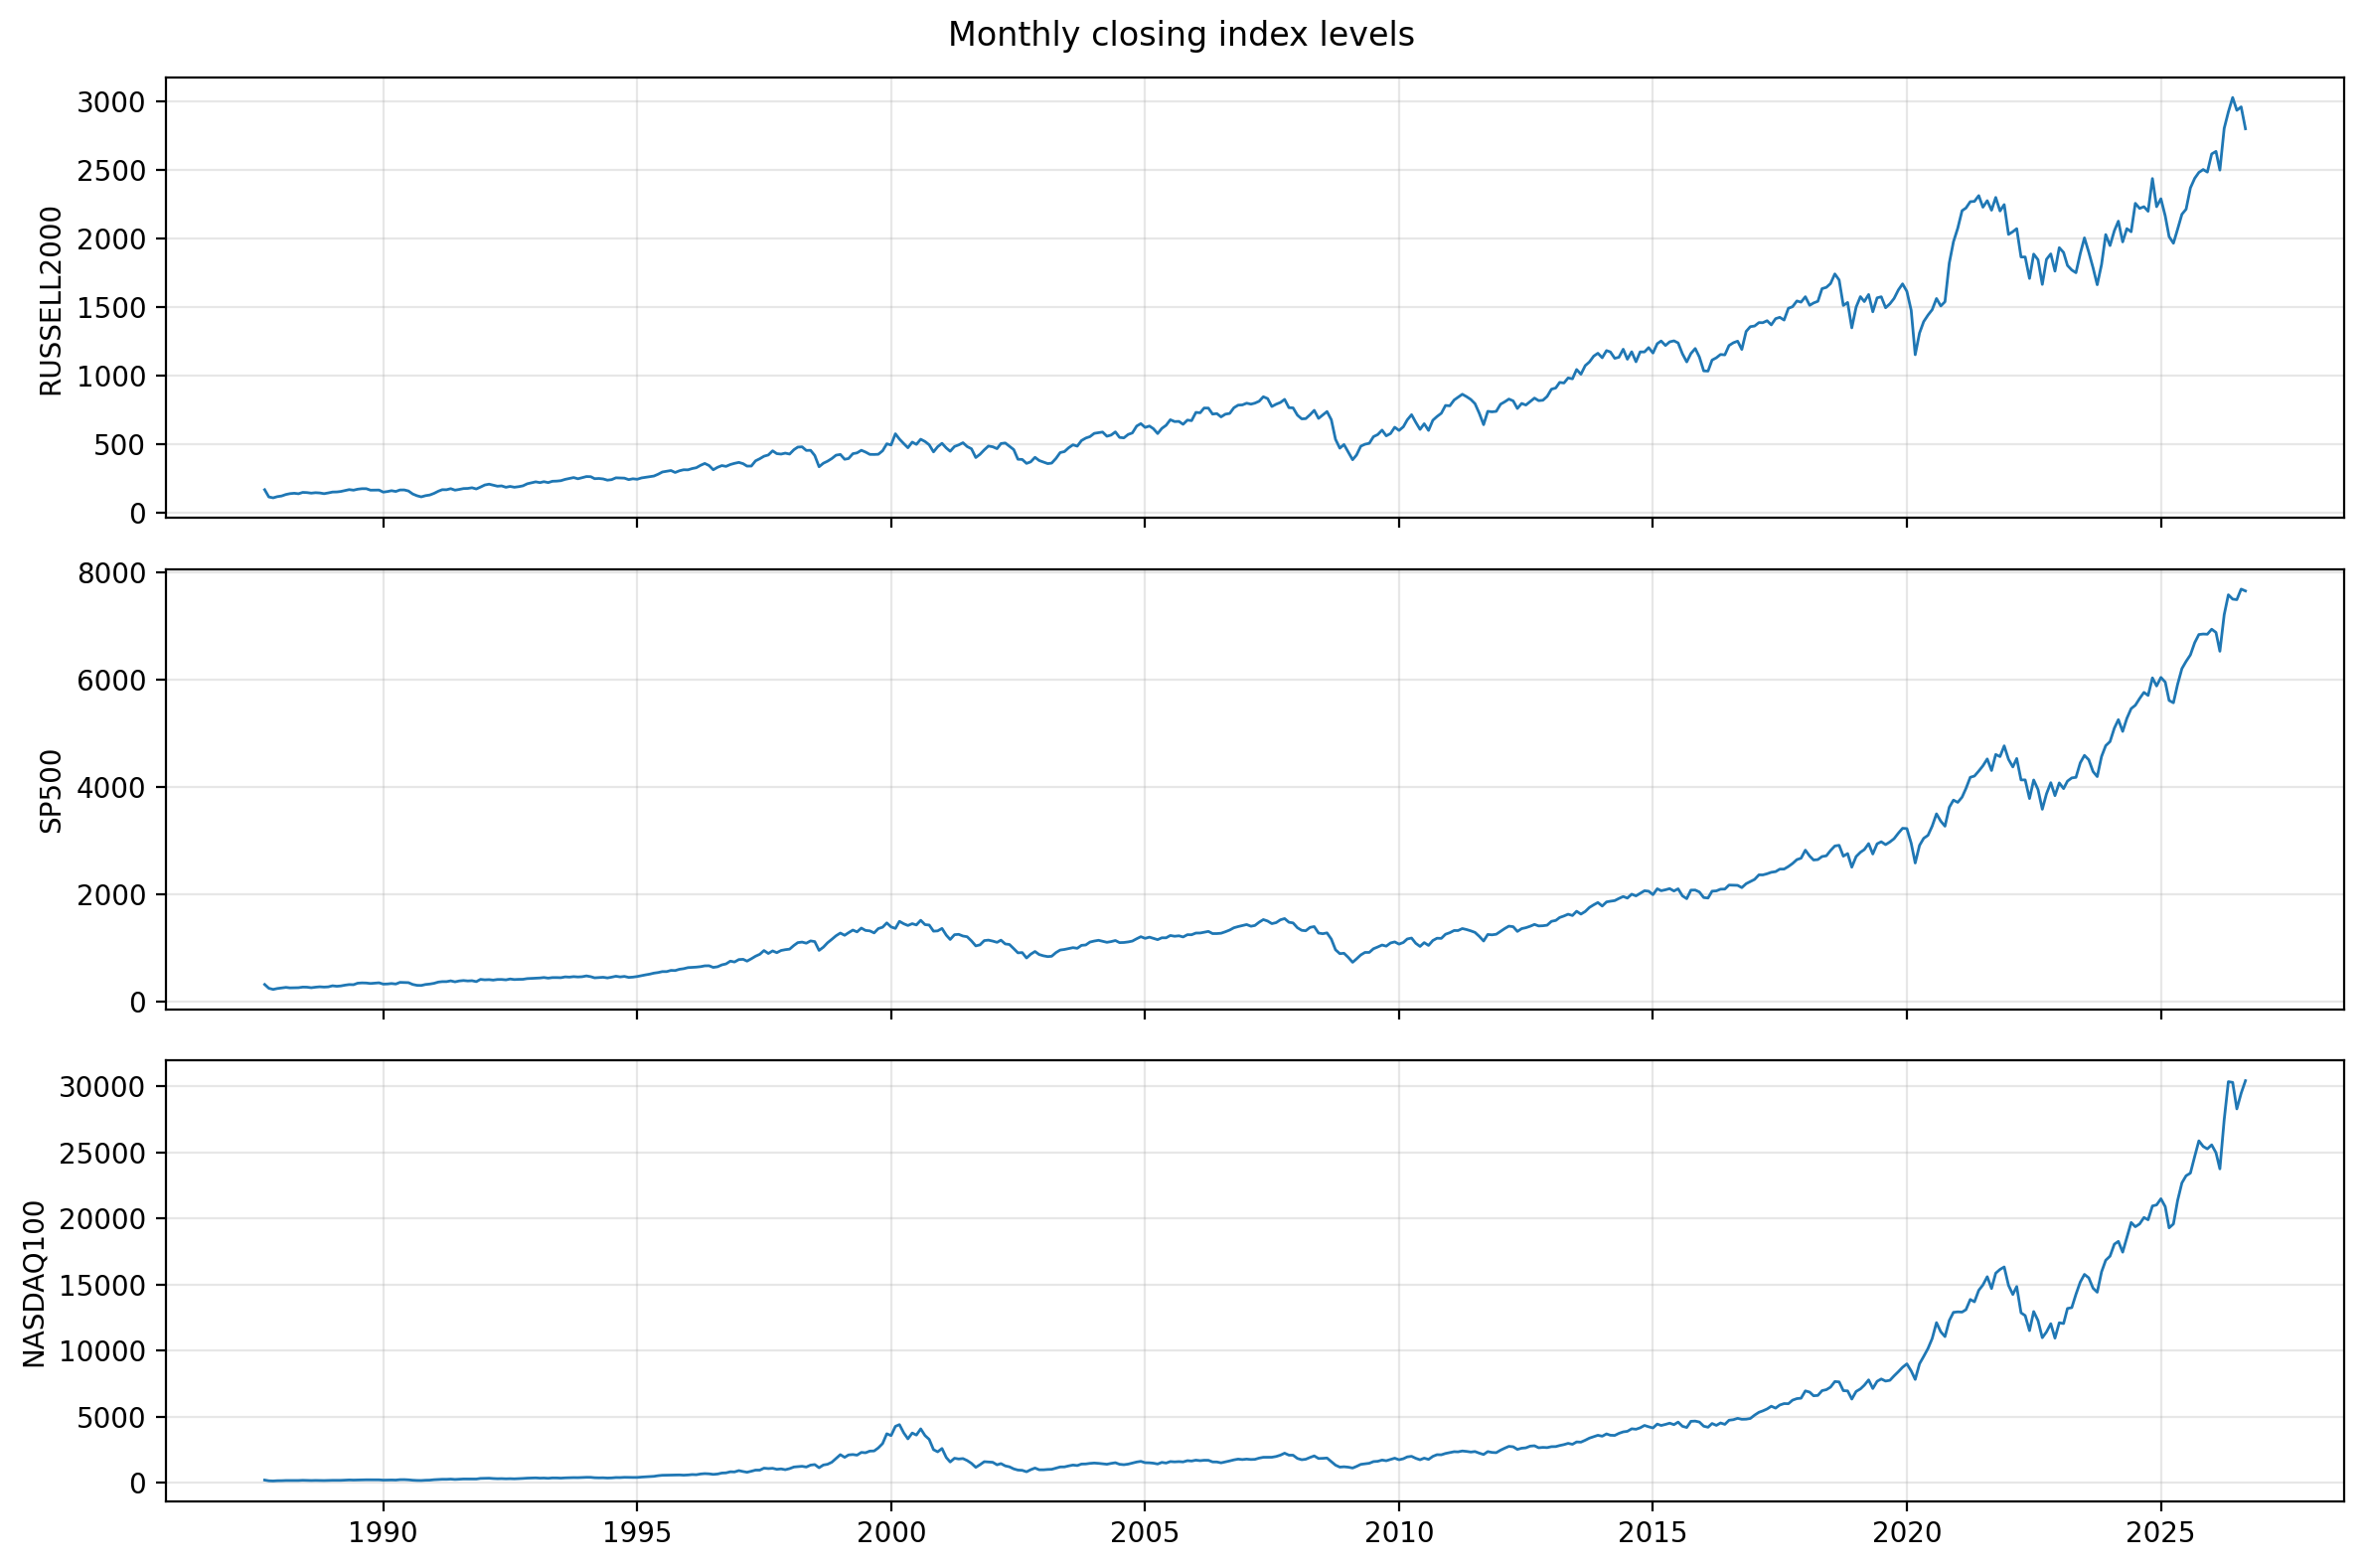

,min,min_date,max,max_date
RUSSELL2000,-36.766620,1987-10-01,16.794266,2020-11-01
SP500,-24.542803,1987-10-01,11.942084,2020-04-01
NASDAQ100,-31.436849,1987-10-01,22.299324,1999-12-01


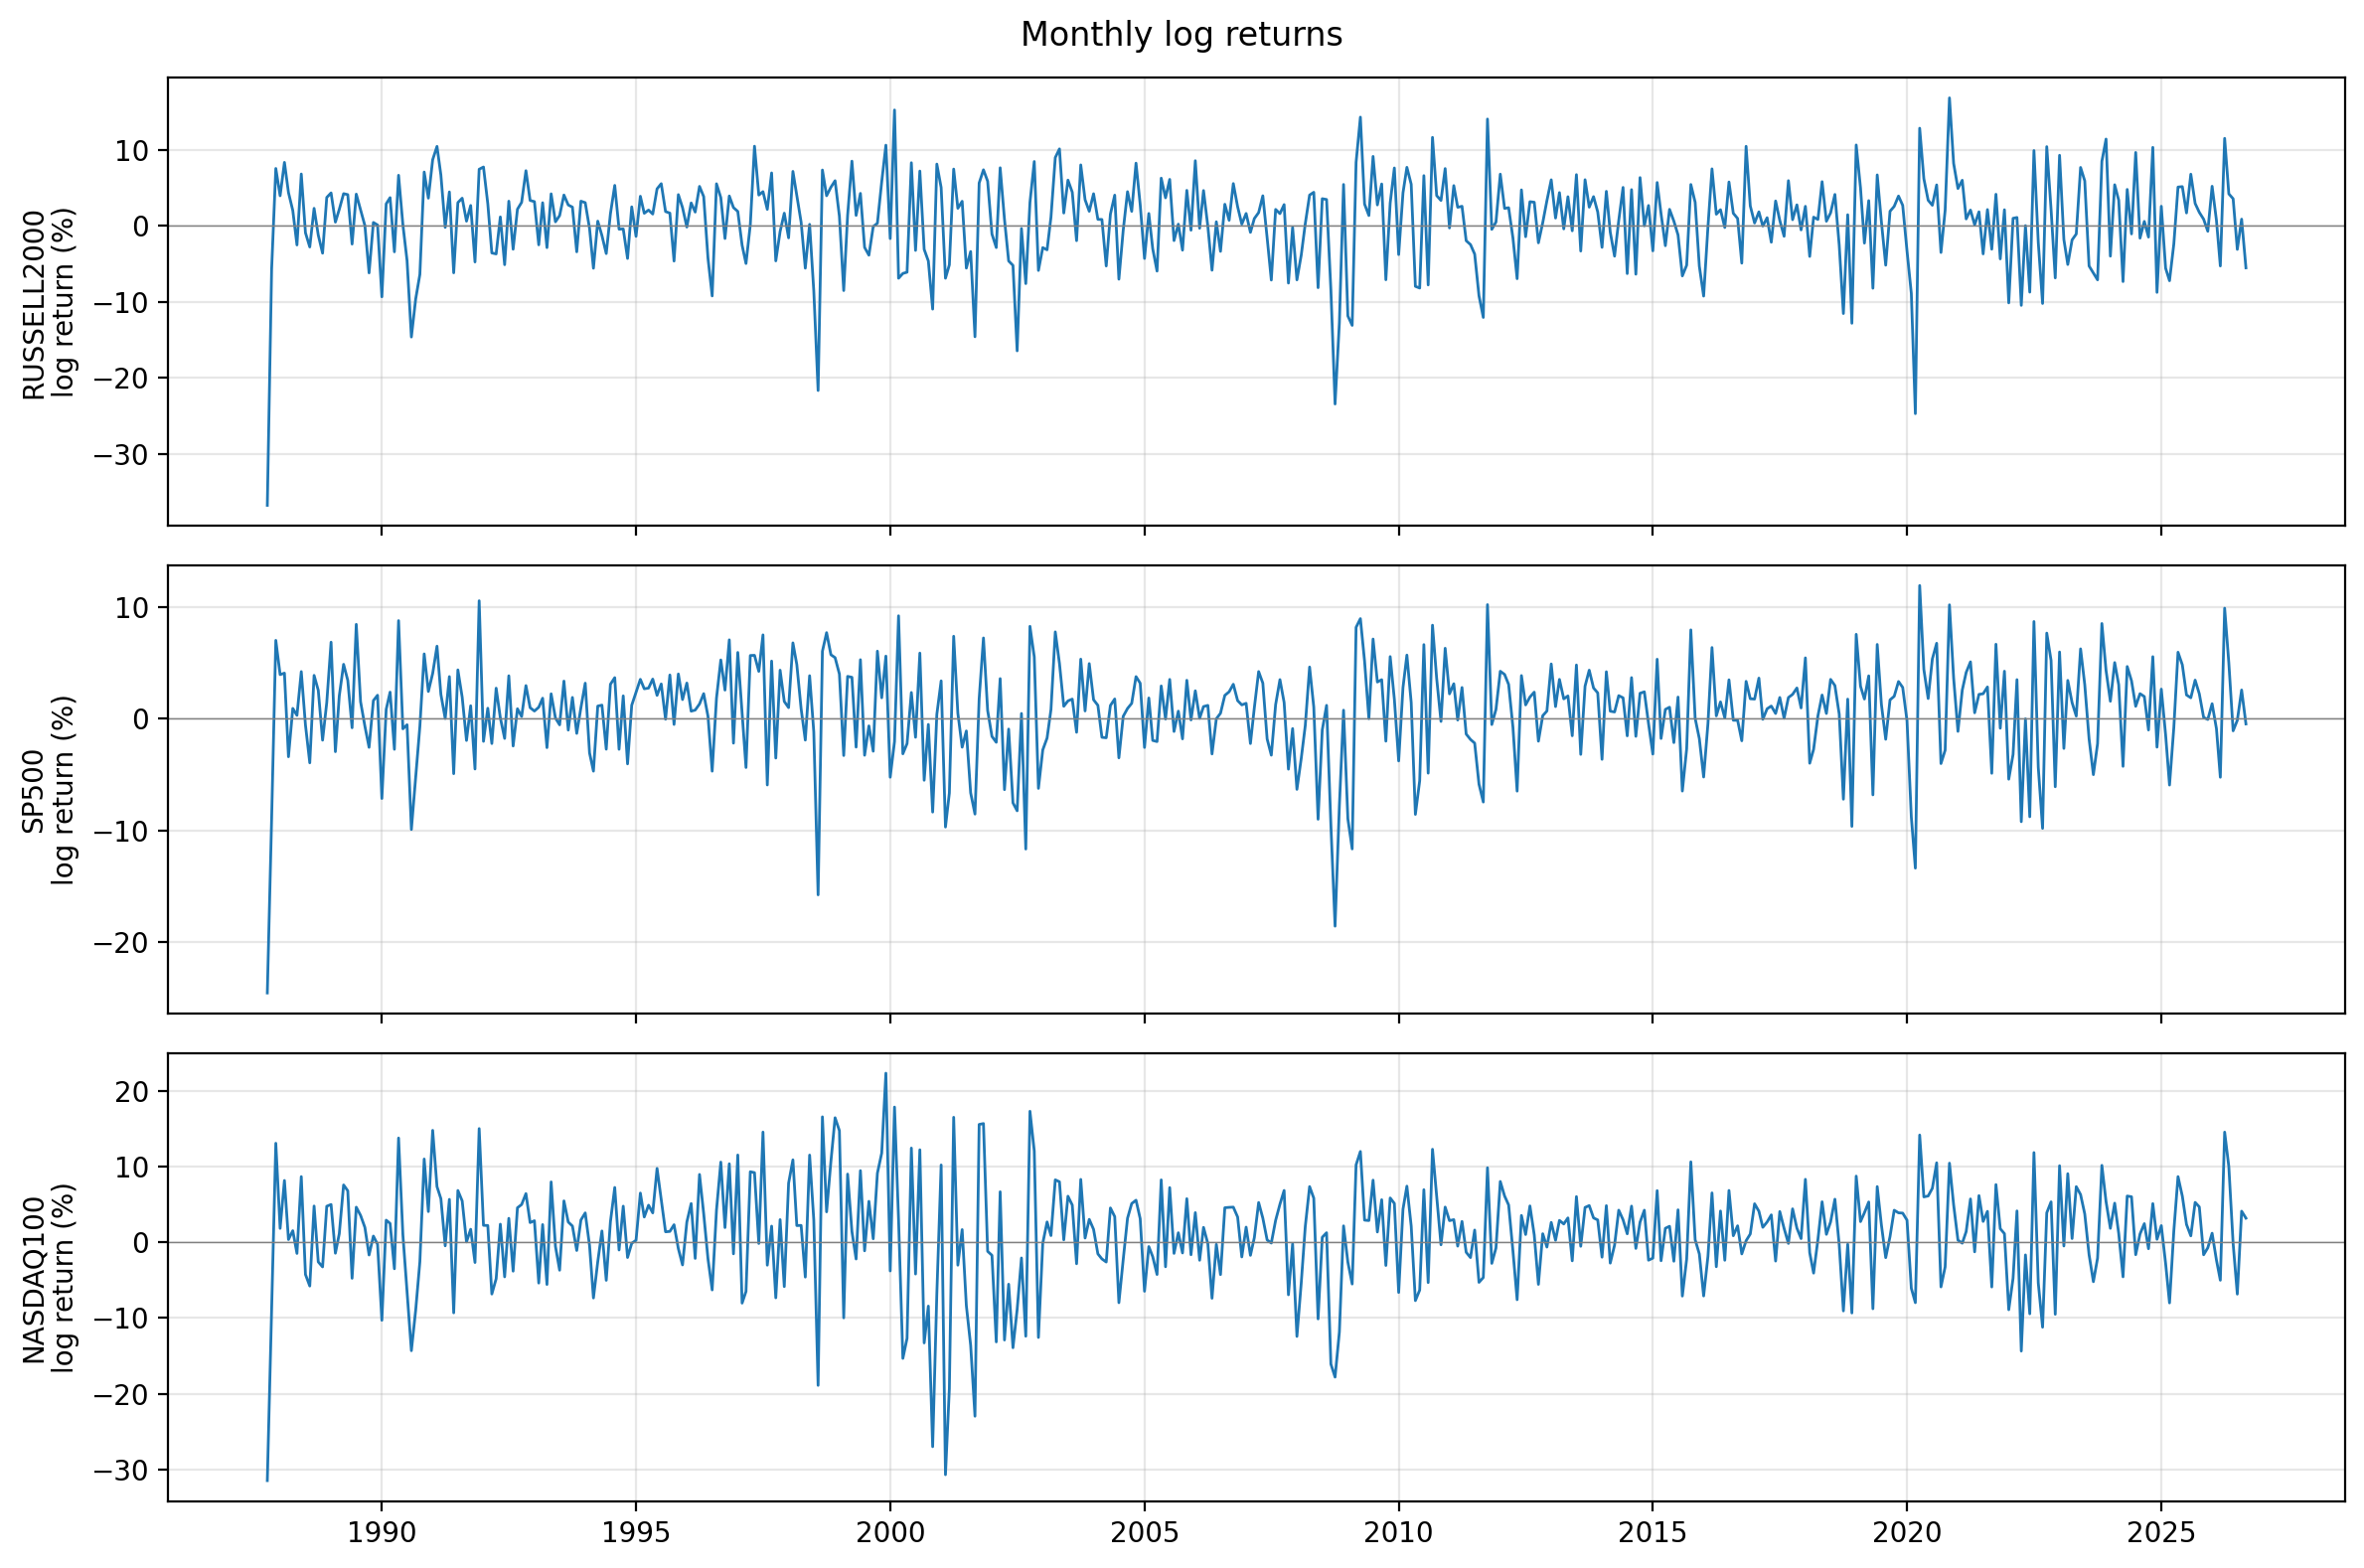

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, col in zip(axes, series_cols):
    ax.plot(prices_clean.index, prices_clean[col], lw=1)
    mask = price_imputed[col]
    if mask.any():
        ax.scatter(prices_clean.index[mask], prices_clean.loc[mask, col], color="red", zorder=3, label="imputed price")
        ax.legend(loc="upper left")
    ax.set_ylabel(col)
    ax.grid(alpha=0.3)
fig.suptitle("Monthly closing index levels")
fig.tight_layout()
plt.show()

extremes = pd.DataFrame({
    "min": market[series_cols].min(),
    "min_date": market[series_cols].idxmin().dt.date,
    "max": market[series_cols].max(),
    "max_date": market[series_cols].idxmax().dt.date,
})
print(extremes)
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, col in zip(axes, series_cols):
    ax.plot(market.index, market[col], lw=1)
    mask = return_imputed[col]
    if mask.any():
        ax.scatter(market.index[mask], market.loc[mask, col], color="red", zorder=3, label="uses imputed price")
        ax.legend(loc="upper left")
    ax.set_ylabel(f"{col}\nlog return (%)")
    ax.axhline(0, color="grey", lw=0.5)
    ax.grid(alpha=0.3)
fig.suptitle("Monthly log returns")
fig.tight_layout()
plt.show()

## Recurrence analysis

Standardize each return series, use Euclidean distances, and choose a separate threshold for 10% off-diagonal recurrence. Defaults: embedding dimension 1, delay 1 month, Theiler minimum separation 12 months. All matrices use the same monthly observations.

In [6]:
# Recurrence plot setup: Euclidean distance on z-scored, delay-embedded series over the full common monthly return window.
# The threshold is set per series by a fixed recurrence rate, so the three RPs are equally dense
# despite having different units and ranges.
from matplotlib import dates as mdates

M, TAU = 1, 1      # embedding dimension and delay (months); m = 1 means the state is the value itself
RR_TARGET = 0.10   # share of off-diagonal pairs counted as recurrent

def embed(x: np.ndarray, m: int, tau: int) -> np.ndarray:
    n = len(x) - (m - 1) * tau
    return np.column_stack([x[i * tau : i * tau + n] for i in range(m)])

def recurrence(series: pd.Series, m: int = M, tau: int = TAU, rr: float = RR_TARGET):
    x = series.to_numpy(dtype=float)
    X = embed((x - x.mean()) / x.std(), m, tau)
    D = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=-1))
    upper = np.triu_indices(len(D), k=1)
    eps = np.quantile(D[upper], rr)
    R = D <= eps
    dates = series.index[(m - 1) * tau :]  # each embedded state is dated by its latest month
    return D, R, eps, dates

def format_date_axes(a) -> None:
    for axis in (a.xaxis, a.yaxis):
        axis.set_major_locator(mdates.YearLocator(10))
        axis.set_major_formatter(mdates.DateFormatter("%Y"))
    a.set_xlabel("month j")
    a.set_ylabel("month i")

def plot_rp(series: pd.Series, m: int = M, tau: int = TAU, rr: float = RR_TARGET) -> np.ndarray:
    D, R, eps, dates = recurrence(series, m, tau, rr)
    actual_rr = R[np.triu_indices(len(R), k=1)].mean()  # ties at eps can push this above the target
    t0, t1 = mdates.date2num(dates[0]), mdates.date2num(dates[-1])
    extent = (t0, t1, t0, t1)

    fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
    im = ax[0].imshow(D, cmap="gist_earth", origin="lower", interpolation="nearest", extent=extent)
    fig.colorbar(im, ax=ax[0], fraction=0.046, pad=0.04, label="distance (std units)")
    ax[0].set_title("Distance matrix")
    ax[1].imshow(R, cmap="copper", origin="lower", interpolation="nearest", extent=extent)
    ax[1].set_title(f"Recurrence plot, ε = {eps:.3f} (RR = {actual_rr:.3f})")
    for a in ax:
        format_date_axes(a)
    fig.suptitle(f"{series.name}: EucD, m = {m}, τ = {tau}, {dates[0]:%Y-%m} to {dates[-1]:%Y-%m}, n = {len(dates)}")
    fig.tight_layout()
    plt.show()
    return R

rps = {}

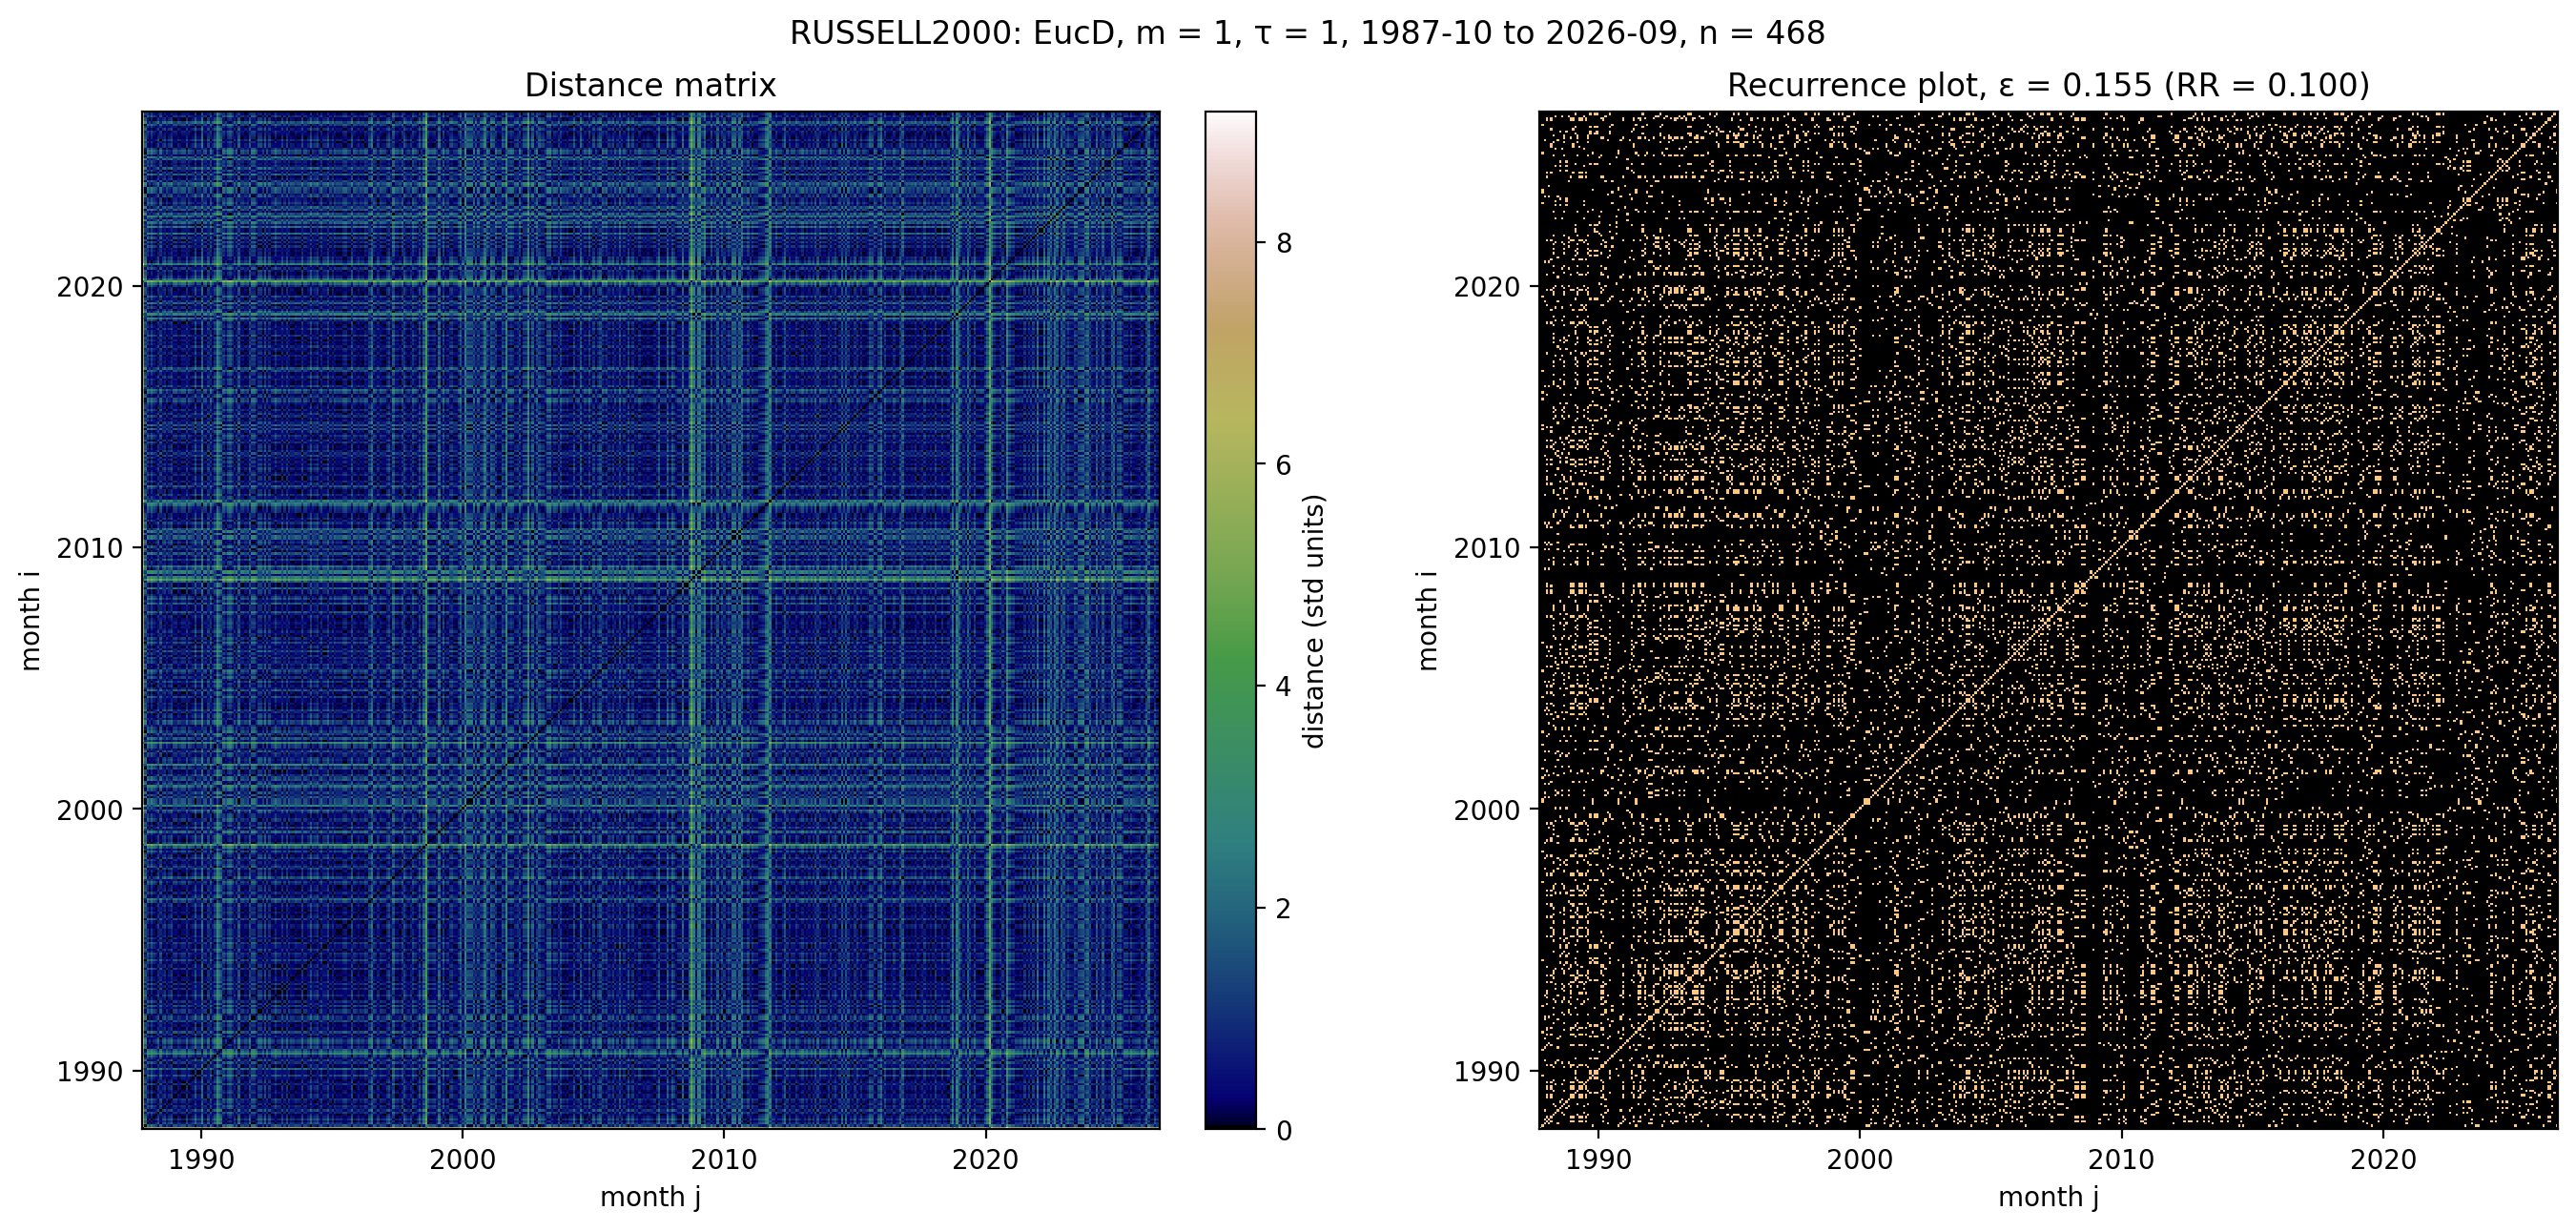

In [7]:
# Russell 2000 log-return RP
rps["RUSSELL2000"] = plot_rp(market["RUSSELL2000"])

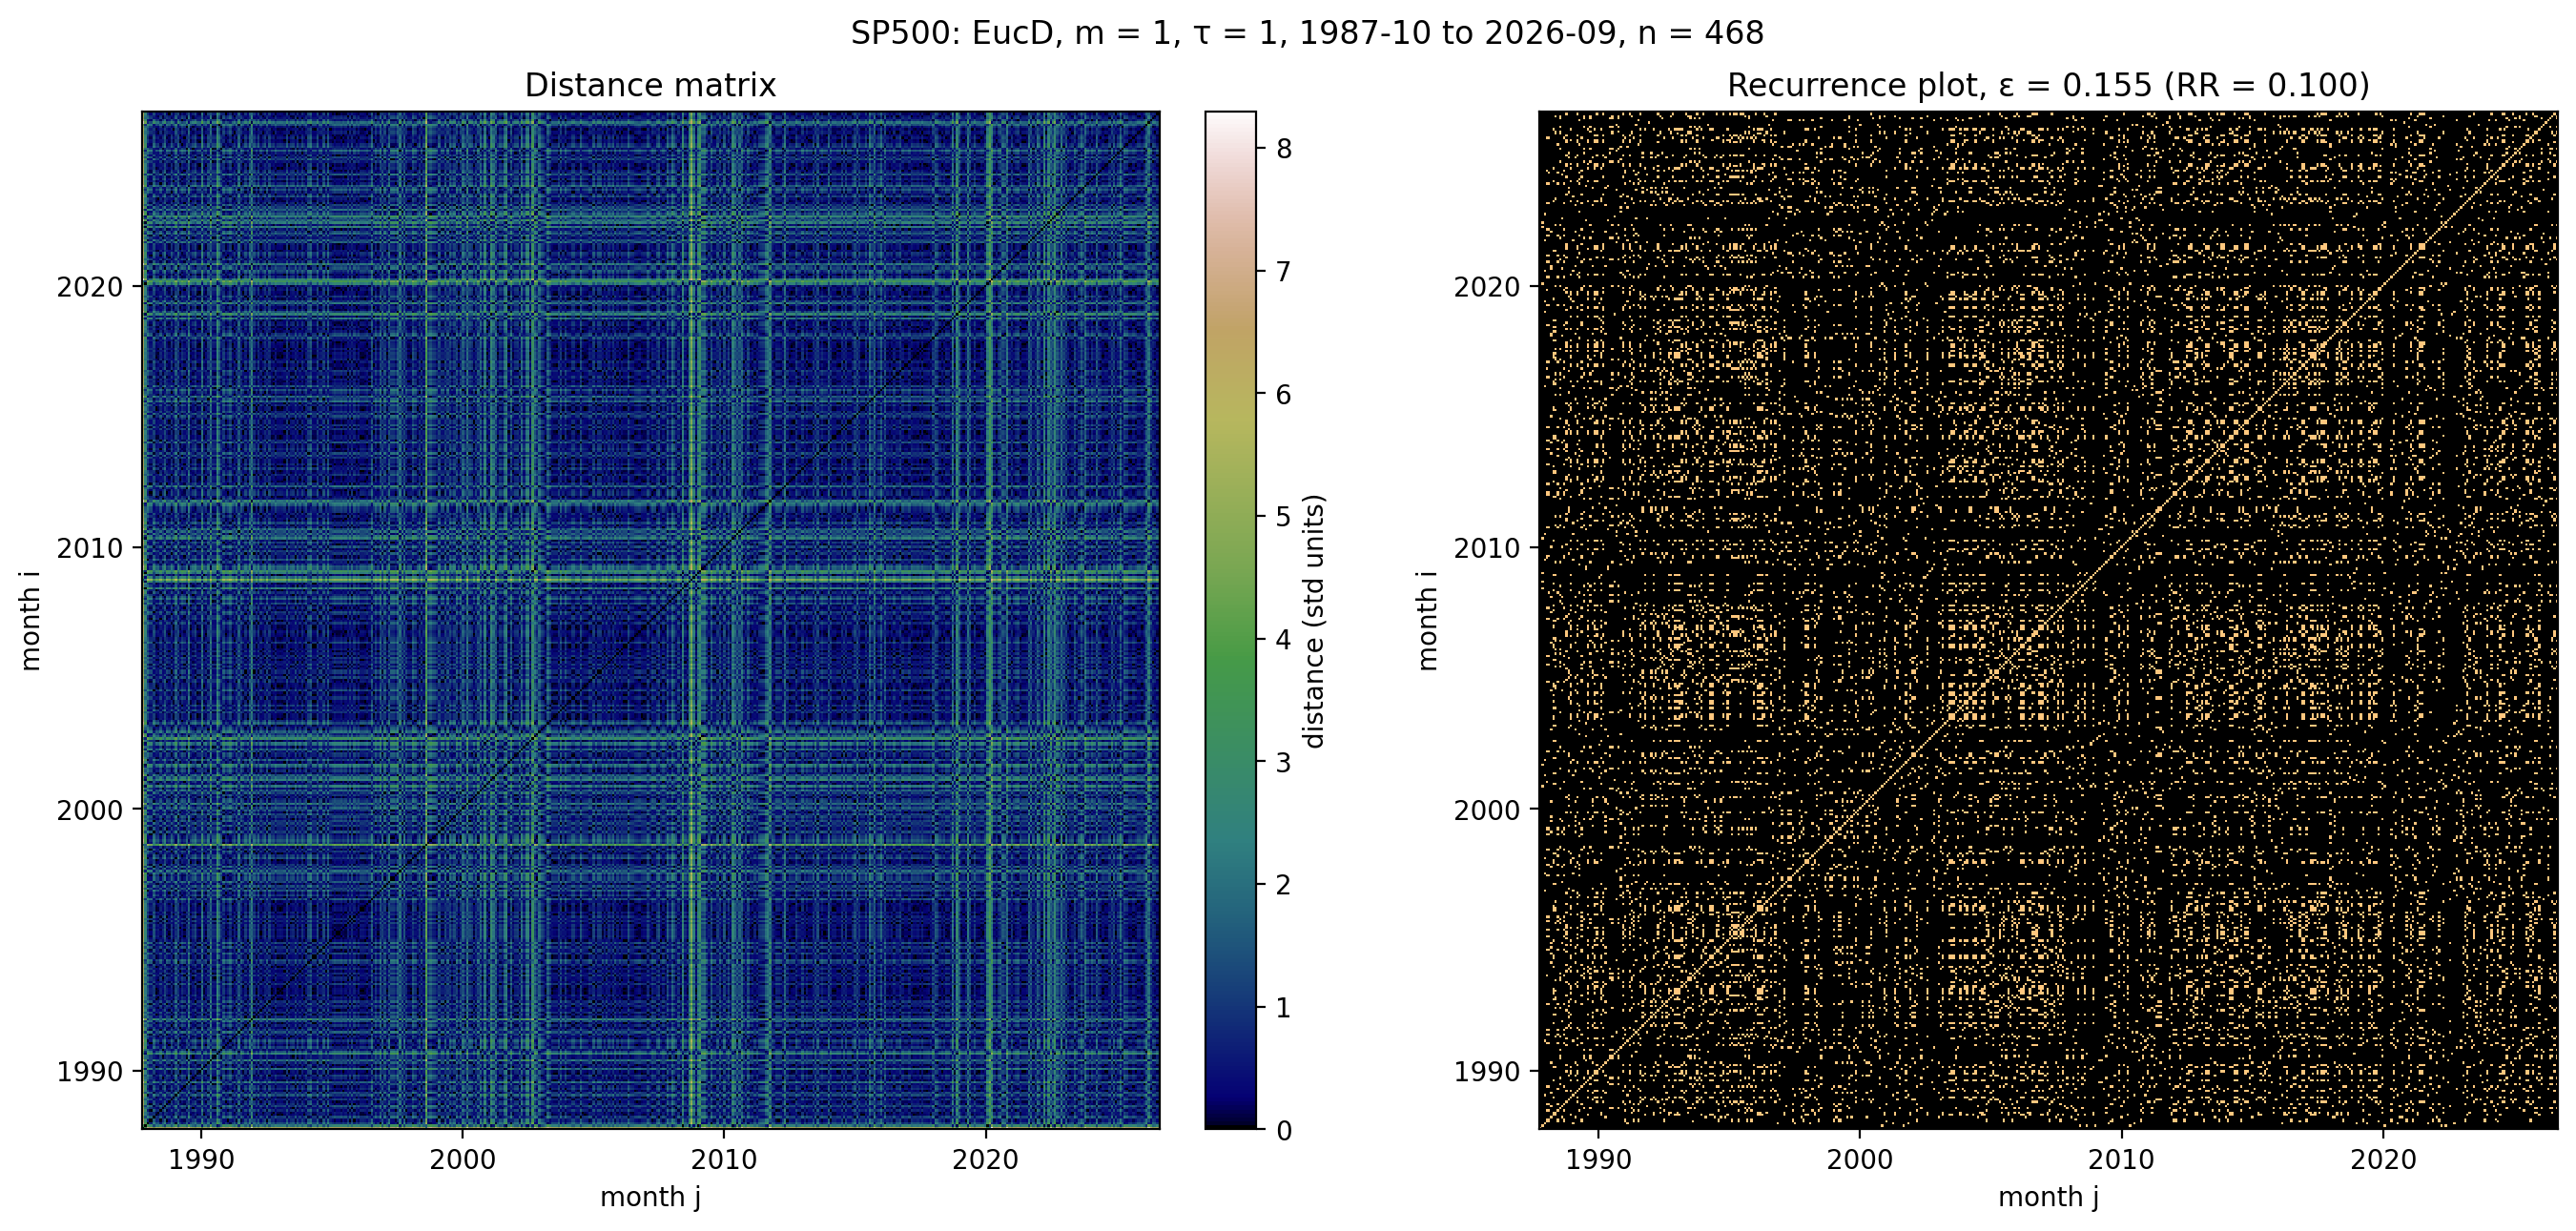

In [8]:
# S&P 500 log-return RP
rps["SP500"] = plot_rp(market["SP500"])

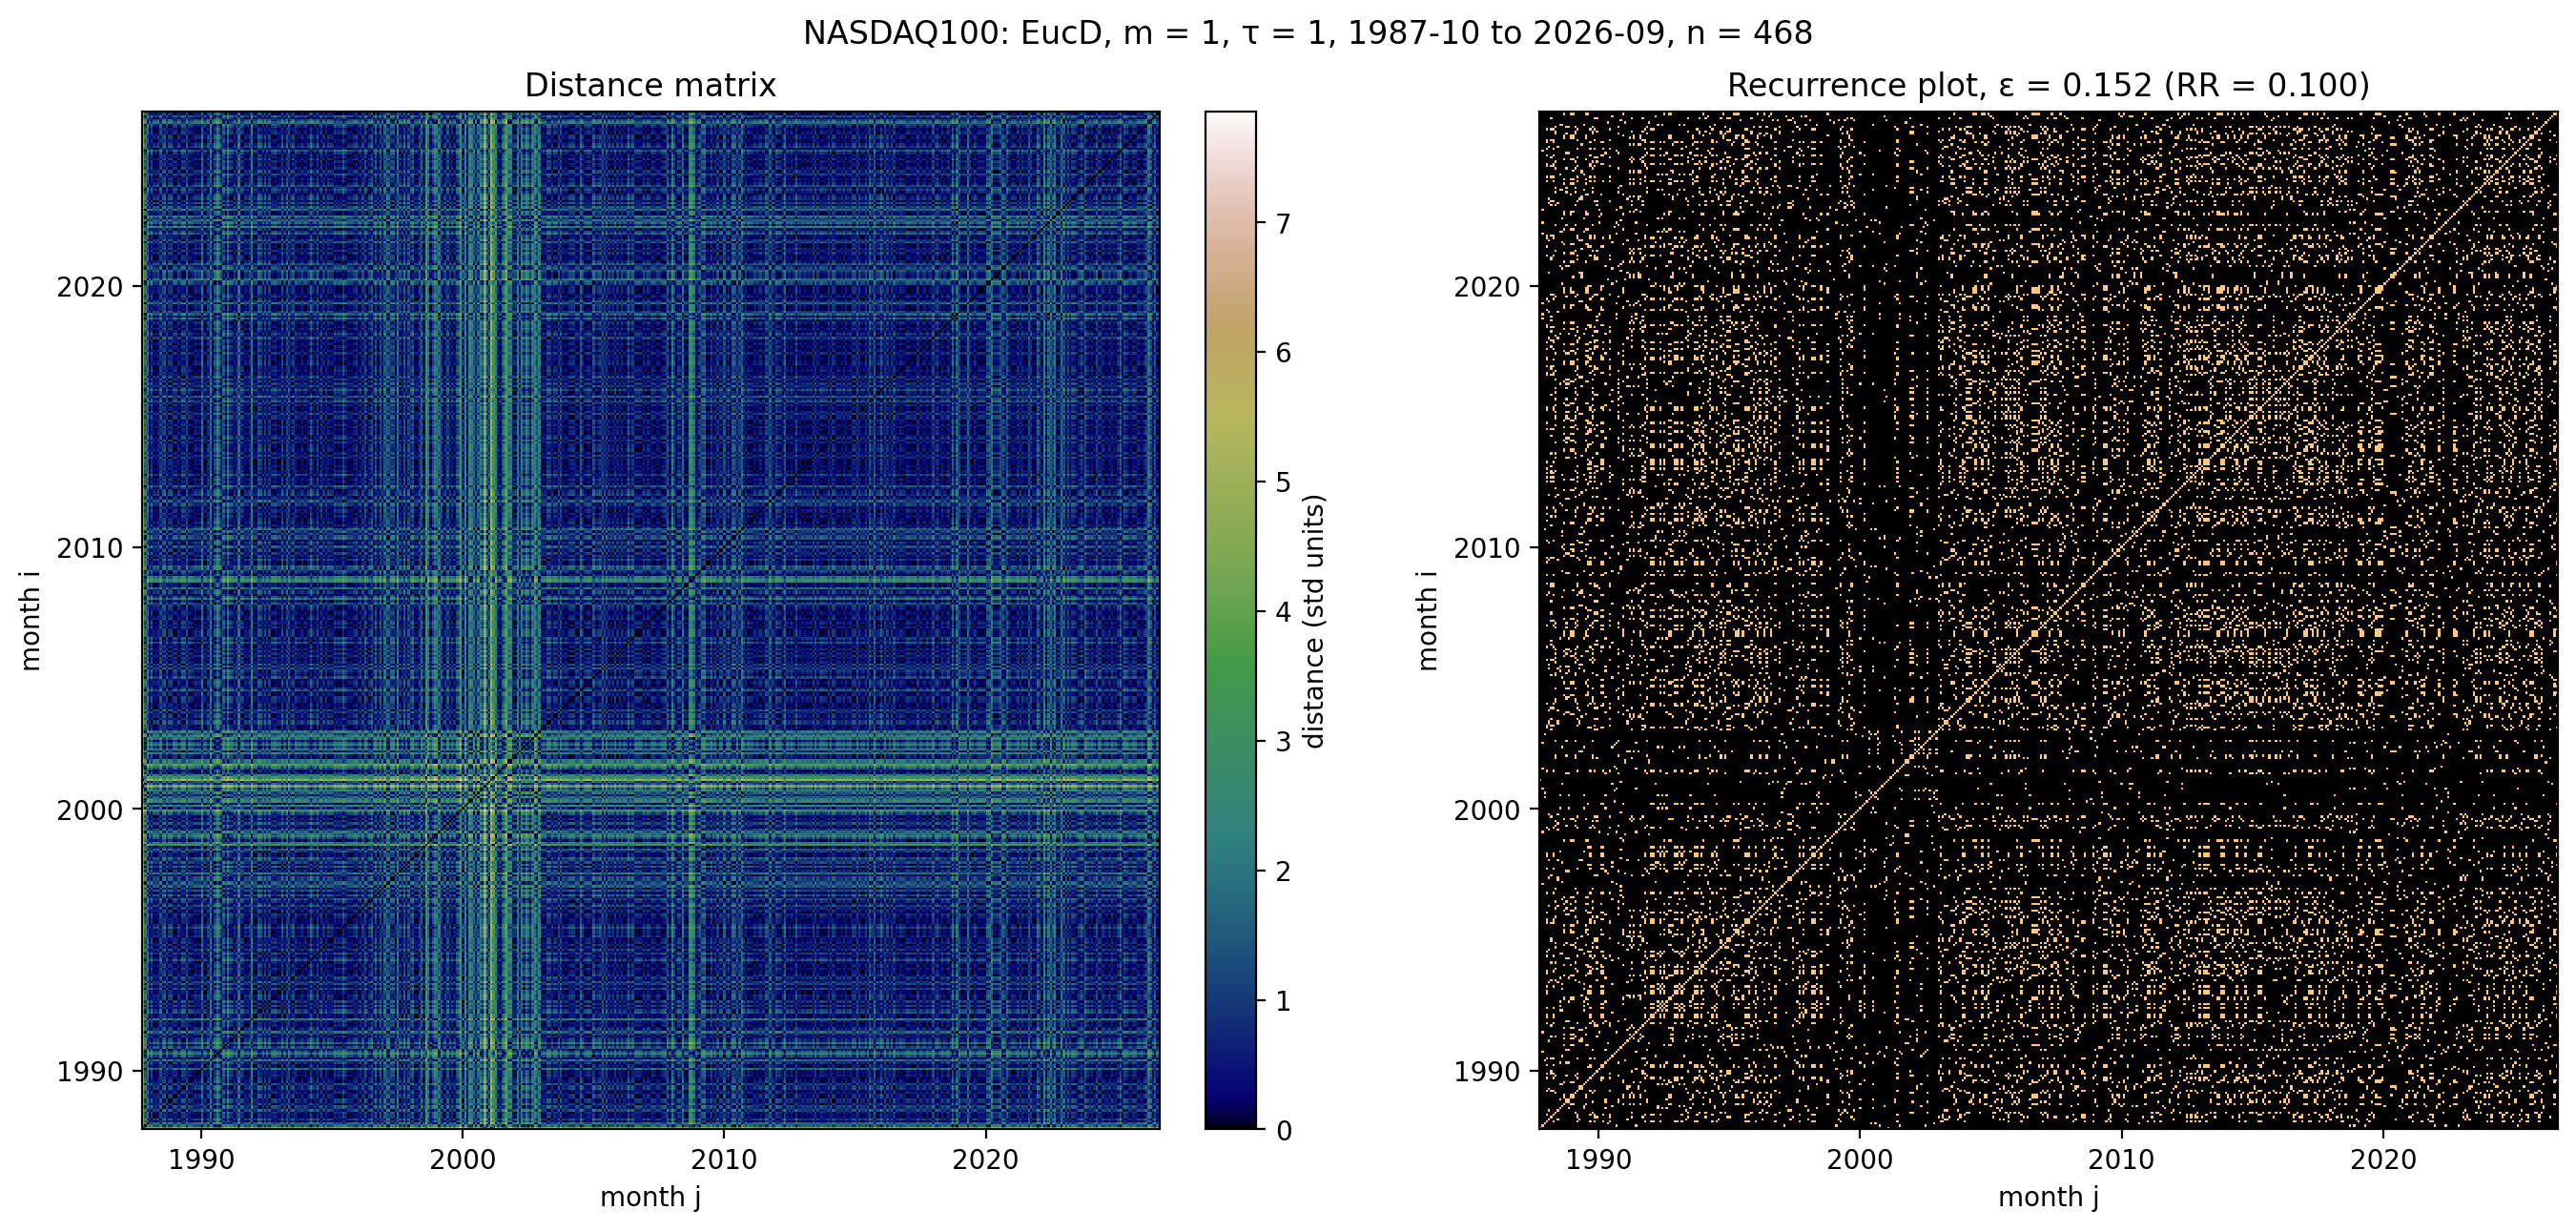

In [9]:
# Nasdaq-100 log-return RP
rps["NASDAQ100"] = plot_rp(market["NASDAQ100"])

In [10]:
# Recurrence independence, per pair and for the trio.
# If the series recurred independently, a month pair (i, j) would be jointly recurrent with probability
# equal to the product of the individual recurrence rates. ratio = observed joint RR / that product
# (1 = no more co-recurrence than chance; > 1 = they revisit their past states together).
from itertools import combinations

N_STATES = len(market) - (M - 1) * TAU
COMBOS = [combo for k in (2, 3) for combo in combinations(series_cols, k)]  # 3 pairs + the trio

def independence_table(min_sep: int = 1) -> pd.DataFrame:
    """Joint vs expected RR, counted over month pairs (i, j) with j - i >= min_sep."""
    idx = np.triu_indices(N_STATES, k=min_sep)
    rr = {c: rps[c][idx].mean() for c in series_cols}
    rows = []
    for combo in COMBOS:
        joint_rr = np.logical_and.reduce([rps[c] for c in combo])[idx].mean()
        expected_rr = np.prod([rr[c] for c in combo])
        rows.append({"systems": " × ".join(combo),
                     **{f"RR {c}": rr[c] for c in combo},
                     "joint RR": joint_rr,
                     "expected if independent": expected_rr,
                     "ratio": joint_rr / expected_rr})
    table = pd.DataFrame(rows).set_index("systems")
    return table[[f"RR {c}" for c in series_cols] + ["joint RR", "expected if independent", "ratio"]]

independence = independence_table()  # all off-diagonal pairs
independence

,RR RUSSELL2000,RR SP500,RR NASDAQ100,joint RR,expected if independent,ratio
systems,,,,,,
RUSSELL2000 × SP500,0.100002,0.100002,NaN,0.018677,0.010,1.867645
RUSSELL2000 × NASDAQ100,0.100002,NaN,0.100002,0.017634,0.010,1.763328
SP500 × NASDAQ100,NaN,0.100002,0.100002,0.021706,0.010,2.170531
RUSSELL2000 × SP500 × NASDAQ100,0.100002,0.100002,0.100002,0.004438,0.001,4.437978


In [11]:
# Theiler window: drop month pairs closer than THEILER months apart.
# Nearby months may share temporal structure or volatility regimes; exclude this local band
# as a sensitivity check, without assuming that returns are smooth. Both the individual and the joint RRs are recomputed on the remaining pairs.
THEILER = 12

independence_theiler = independence_table(min_sep=THEILER)
independence_theiler

,RR RUSSELL2000,RR SP500,RR NASDAQ100,joint RR,expected if independent,ratio
systems,,,,,,
RUSSELL2000 × SP500,0.099476,0.099447,NaN,0.018532,0.009893,1.873356
RUSSELL2000 × NASDAQ100,0.099476,NaN,0.099802,0.017429,0.009928,1.755521
SP500 × NASDAQ100,NaN,0.099447,0.099802,0.021450,0.009925,2.161192
RUSSELL2000 × SP500 × NASDAQ100,0.099476,0.099447,0.099802,0.004309,0.000987,4.364595


In [12]:
# Doubly and triply joint covariance and correlation of the recurrence indicators.
# Each month pair (i, j) is one observation; R_X[i, j] is a 0/1 variable with mean q_X = RR_X.
#
# Pairs (2nd order):
#   Cov_XY  = E[(R_X - q_X)(R_Y - q_Y)] = q_XY - q_X q_Y                (joint RR minus its independence value)
#   corr_XY = Cov_XY / (σ_X σ_Y),  σ_X = sqrt(q_X (1 - q_X))           (phi coefficient, in [-1, 1])
#
# Trio (3rd-order joint cumulant):
#   Cov_XYZ = E[(R_X - q_X)(R_Y - q_Y)(R_Z - q_Z)]
#           = q_XYZ - q_X q_YZ - q_Y q_XZ - q_Z q_XY + 2 q_X q_Y q_Z
#   It is 0 whenever one series is independent of the other two, even if those two are linked. It removes pairwise-product terms from D_3,
#   but a nonzero value alone does not prove a genuine three-way interaction.
#   corr_XYZ = Cov_XYZ / (‖R_X - q_X‖₃ ‖R_Y - q_Y‖₃ ‖R_Z - q_Z‖₃),  ‖a‖₃ = E[|a|³]^(1/3).
#   Hölder's inequality bounds this in [-1, 1]. Dividing by σ_X σ_Y σ_Z (standard coskewness) is not bounded
#   here: with q ≈ 0.1 the indicators are very skewed and that ratio can exceed 1.

def dependence_table(min_sep: int = 1) -> pd.DataFrame:
    """Joint covariance / correlation over month pairs (i, j) with j - i >= min_sep."""
    idx = np.triu_indices(N_STATES, k=min_sep)
    centred = {c: rps[c][idx] - rps[c][idx].mean() for c in series_cols}
    rows = []
    for combo in COMBOS:
        parts = [centred[c] for c in combo]
        cov = np.prod(parts, axis=0).mean()
        if len(combo) == 2:
            scale = np.prod([np.sqrt(np.mean(p ** 2)) for p in parts])
        else:
            scale = np.prod([np.mean(np.abs(p) ** 3) ** (1 / 3) for p in parts])
        rows.append({"systems": " × ".join(combo), "order": len(combo),
                     "joint covariance": cov, "joint correlation": cov / scale})
    return pd.DataFrame(rows).set_index("systems")

dependence = dependence_table()                         # all off-diagonal pairs
dependence_theiler = dependence_table(min_sep=THEILER)  # pairs at least THEILER months apart
pd.concat({"all pairs": dependence.drop(columns="order"),
           f"Theiler {THEILER}": dependence_theiler.drop(columns="order")}, axis=1)

all pairs  ...        Theiler 12
                                joint covariance  ... joint correlation
systems                                           ...                  
RUSSELL2000 × SP500                     0.008677  ...          0.096459
RUSSELL2000 × NASDAQ100                 0.007634  ...          0.083610
SP500 × NASDAQ100                       0.011706  ...          0.128483
RUSSELL2000 × SP500 × NASDAQ100         0.000637  ...          0.007709

[4 rows x 4 columns]

In [13]:
# # Time-shift surrogate test.
# # Rotating a series by s months rotates its RP along both axes: R_shifted[i, j] = R[i - s, j - s].
# # Its own recurrence structure (including the dense diagonal band) is kept, only its alignment with the
# # other series is broken. Over many shifts this gives the joint RR expected with no link but the same
# # autocorrelation; the observed joint RR is compared with that null distribution.
# MIN_SHIFT = 60        # months; shorter shifts could leave the series in the same business cycle
# N_TRIO_DRAWS = 1000   # random (s1, s2) shift combinations for the trio
# rng = np.random.default_rng(42)

# upper = np.triu_indices(N_STATES, k=1)
# valid_shifts = np.arange(MIN_SHIFT, N_STATES - MIN_SHIFT + 1)

# def shift_rp(R: np.ndarray, s: int) -> np.ndarray:
#     return np.roll(R, (s, s), axis=(0, 1))

# def joint_rr_of(mats) -> float:
#     return np.logical_and.reduce(mats)[upper].mean()

# rows = []
# for combo in COMBOS:
#     anchor, *others = combo  # the first series stays fixed, the others are shifted
#     observed = joint_rr_of([rps[c] for c in combo])
#     if len(others) == 1:
#         shift_sets = [(s,) for s in valid_shifts]  # every admissible shift
#     else:
#         shift_sets = []
#         while len(shift_sets) < N_TRIO_DRAWS:
#             s1, s2 = rng.choice(valid_shifts, size=2)
#             if MIN_SHIFT <= (s1 - s2) % N_STATES <= N_STATES - MIN_SHIFT:  # shifted series also misaligned with each other
#                 shift_sets.append((s1, s2))
#     null = np.array([joint_rr_of([rps[anchor]] + [shift_rp(rps[c], s) for c, s in zip(others, shifts)])
#                      for shifts in shift_sets])
#     rows.append({"systems": " × ".join(combo),
#                  "joint RR": observed,
#                  "null mean": null.mean(),
#                  "null 95%": np.quantile(null, 0.95),
#                  "ratio vs null": observed / null.mean(),
#                  "p-value": (1 + (null >= observed).sum()) / (1 + len(null)),
#                  "surrogates": len(null)})
# independence_shift = pd.DataFrame(rows).set_index("systems")
# independence_shift

In [14]:
# Pair RPs: joint recurrence. 
# Months (i, j) are jointly recurrent when BOTH series recur there: JR = R_X AND R_Y.
# Each series keeps its own ε from cell 6, so different units never get mixed in one distance.
# Cross RPs (X at month i vs Y at month j) are not used: they need both series in one shared state space.
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

OVERLAY_CMAP = ListedColormap(["black", "tab:blue", "tab:orange", "white"])

def plot_jrp(a: str, b: str) -> np.ndarray:
    Ra, Rb = rps[a], rps[b]
    JR = Ra & Rb
    stats = independence.loc[f"{a} × {b}"]
    dates = market.index[(M - 1) * TAU :]
    t0, t1 = mdates.date2num(dates[0]), mdates.date2num(dates[-1])
    extent = (t0, t1, t0, t1)

    fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
    overlay = Ra.astype(int) + 2 * Rb.astype(int)  # 0 neither, 1 a only, 2 b only, 3 both
    ax[0].imshow(overlay, cmap=OVERLAY_CMAP, vmin=-0.5, vmax=3.5, origin="lower", interpolation="nearest", extent=extent)
    ax[0].legend(handles=[Patch(color="tab:blue", label=f"{a} only"),
                          Patch(color="tab:orange", label=f"{b} only"),
                          Patch(facecolor="white", edgecolor="grey", label="both")],
                 loc="upper left", fontsize=8, framealpha=0.9)
    ax[0].set_title("Individual RPs overlaid")
    ax[1].imshow(JR, cmap="copper", origin="lower", interpolation="nearest", extent=extent)
    ax[1].set_title(f"Joint recurrence plot, RR = {stats['joint RR']:.4f} ({stats['ratio']:.1f}× independence)")
    for x in ax:
        format_date_axes(x)
    fig.suptitle(f"{a} × {b}: EucD, m = {M}, τ = {TAU}, {dates[0]:%Y-%m} to {dates[-1]:%Y-%m}, n = {len(dates)}")
    fig.tight_layout()
    plt.show()
    return JR

jrps = {}

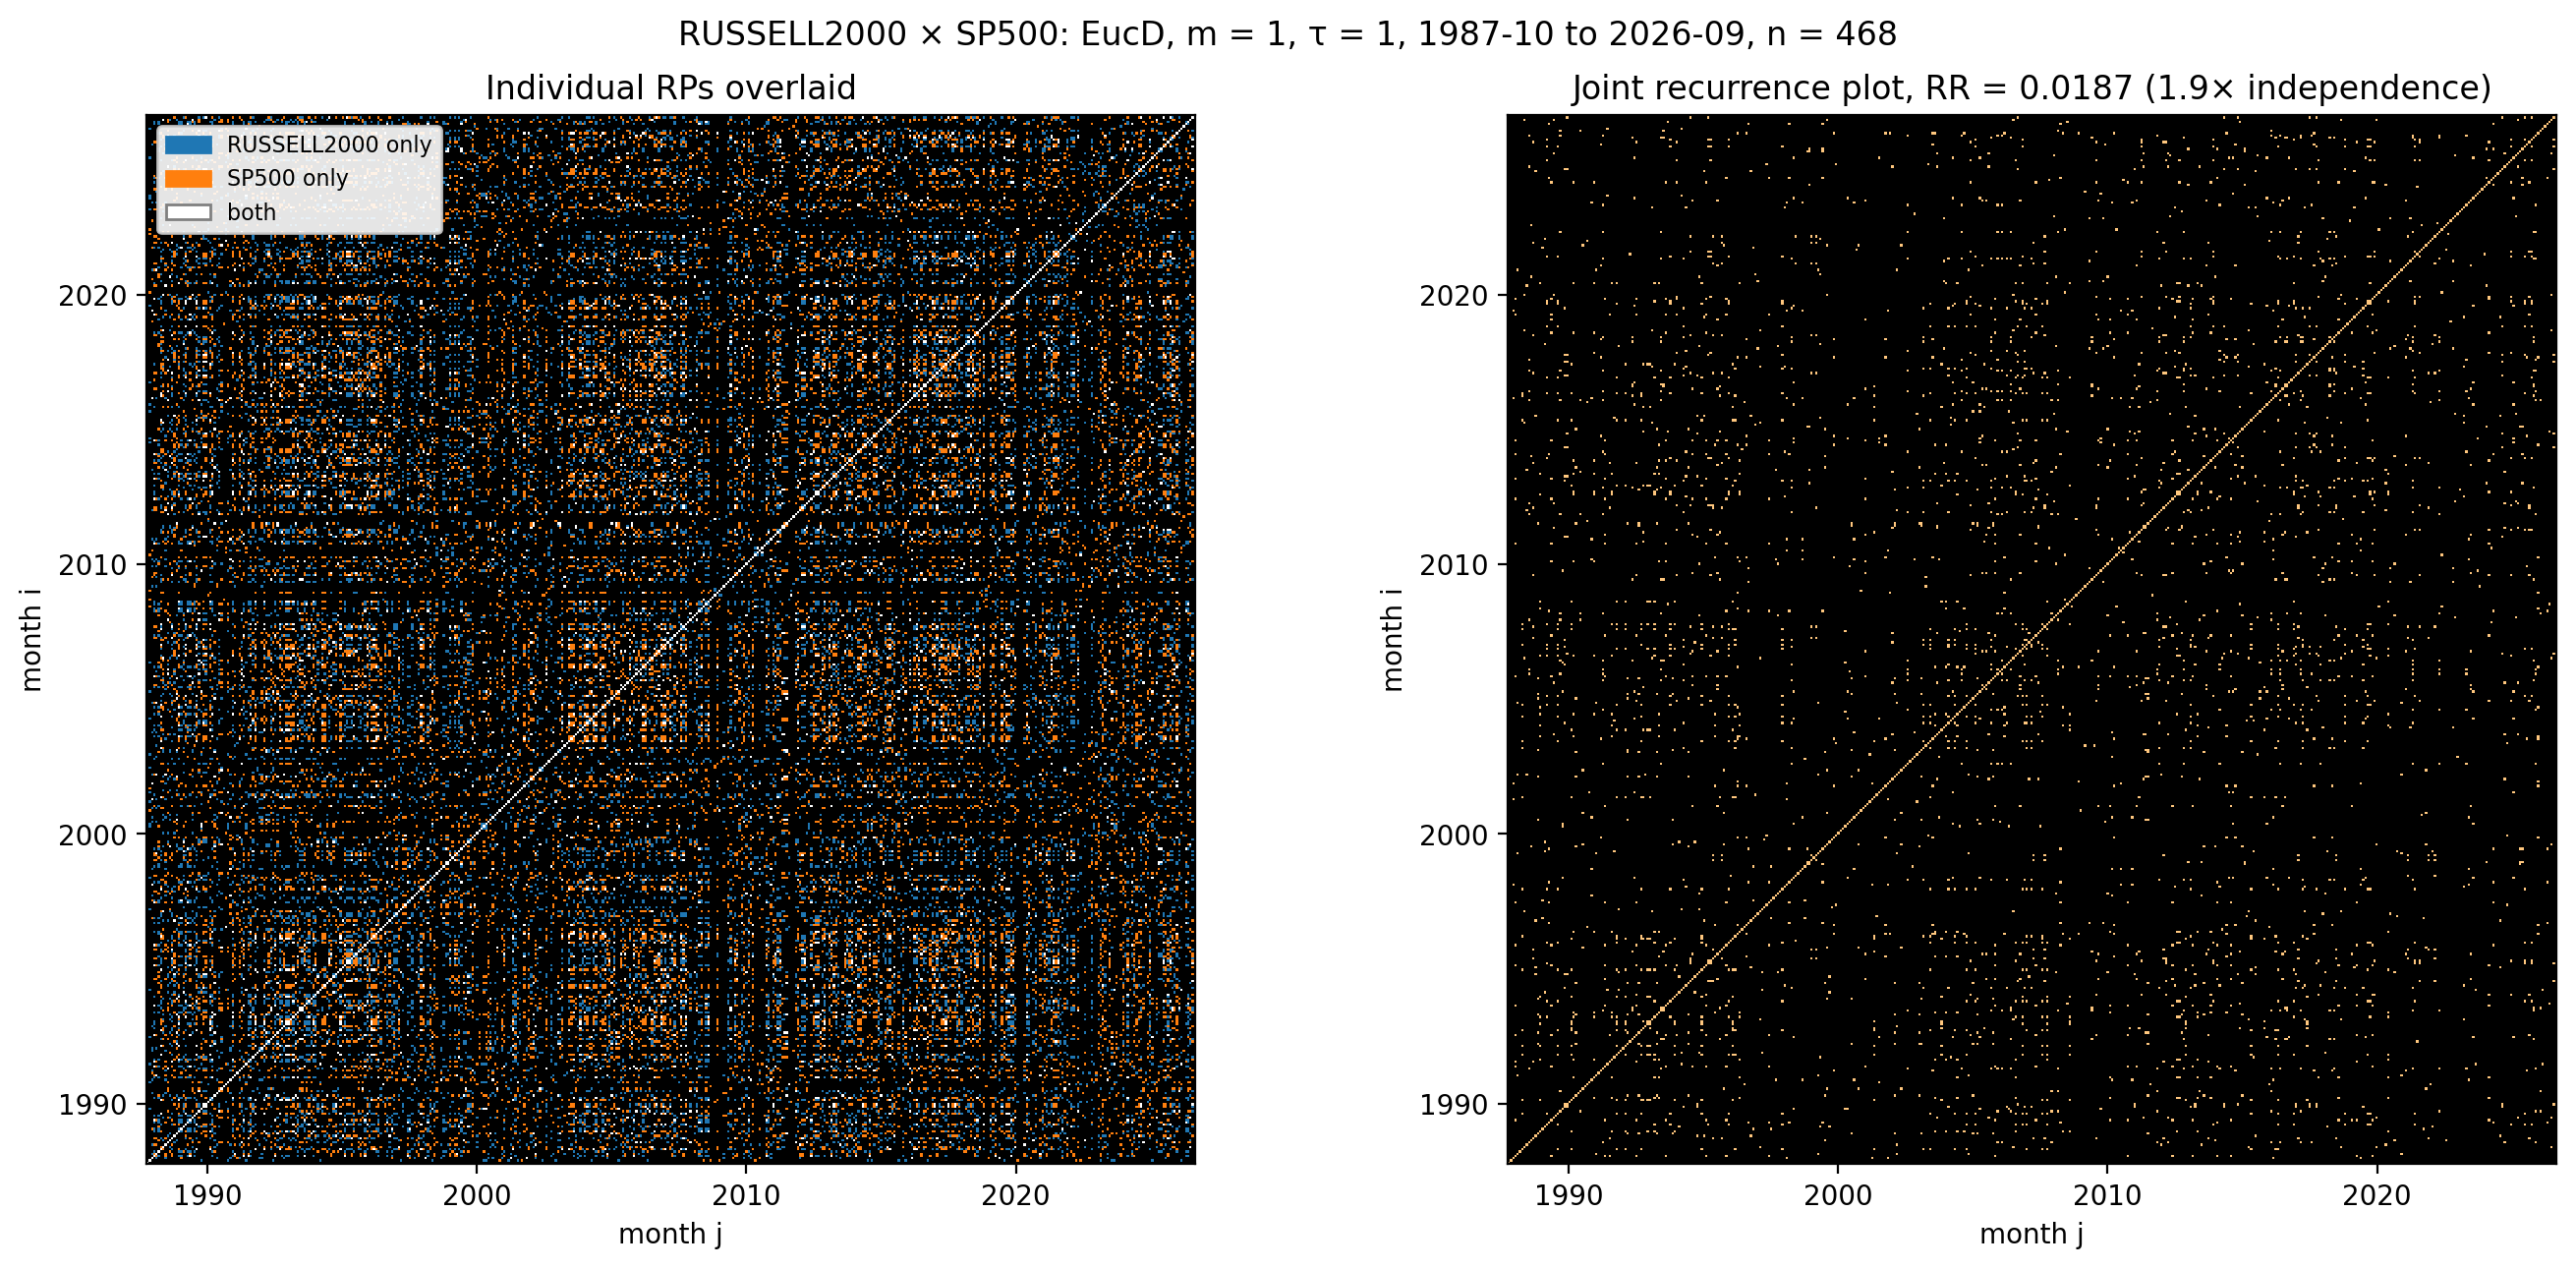

In [15]:
# Russell 2000 x S&P 500 JRP
jrps[("RUSSELL2000", "SP500")] = plot_jrp("RUSSELL2000", "SP500")

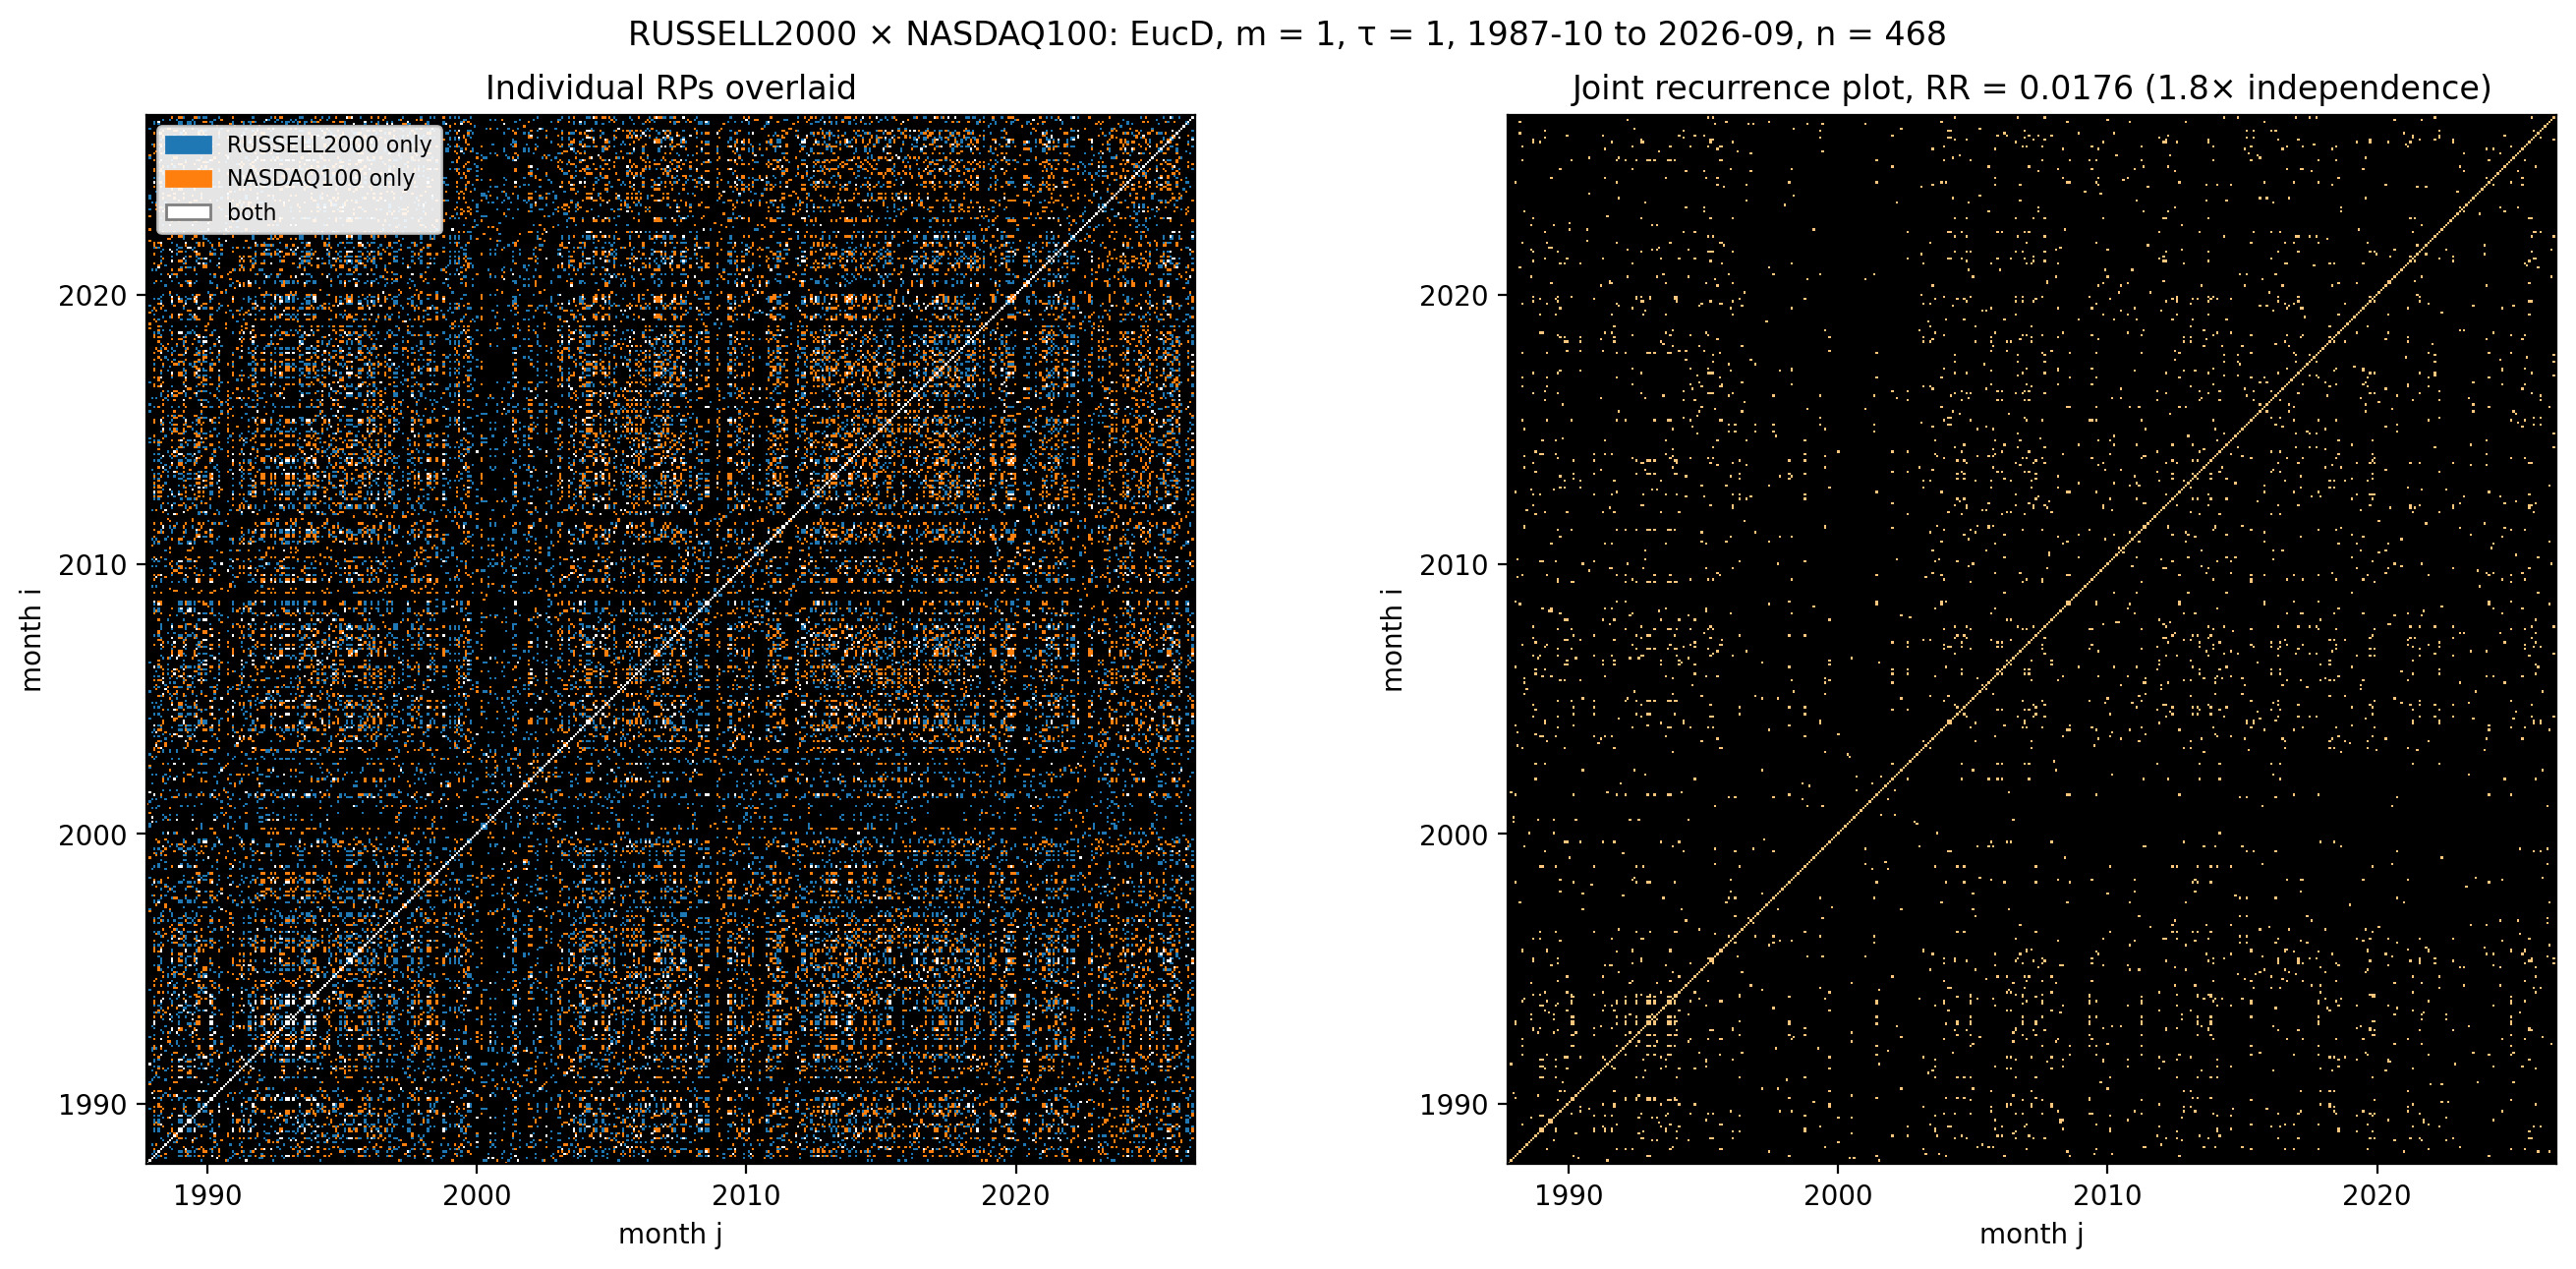

In [16]:
# Russell 2000 x Nasdaq-100 JRP
jrps[("RUSSELL2000", "NASDAQ100")] = plot_jrp("RUSSELL2000", "NASDAQ100")

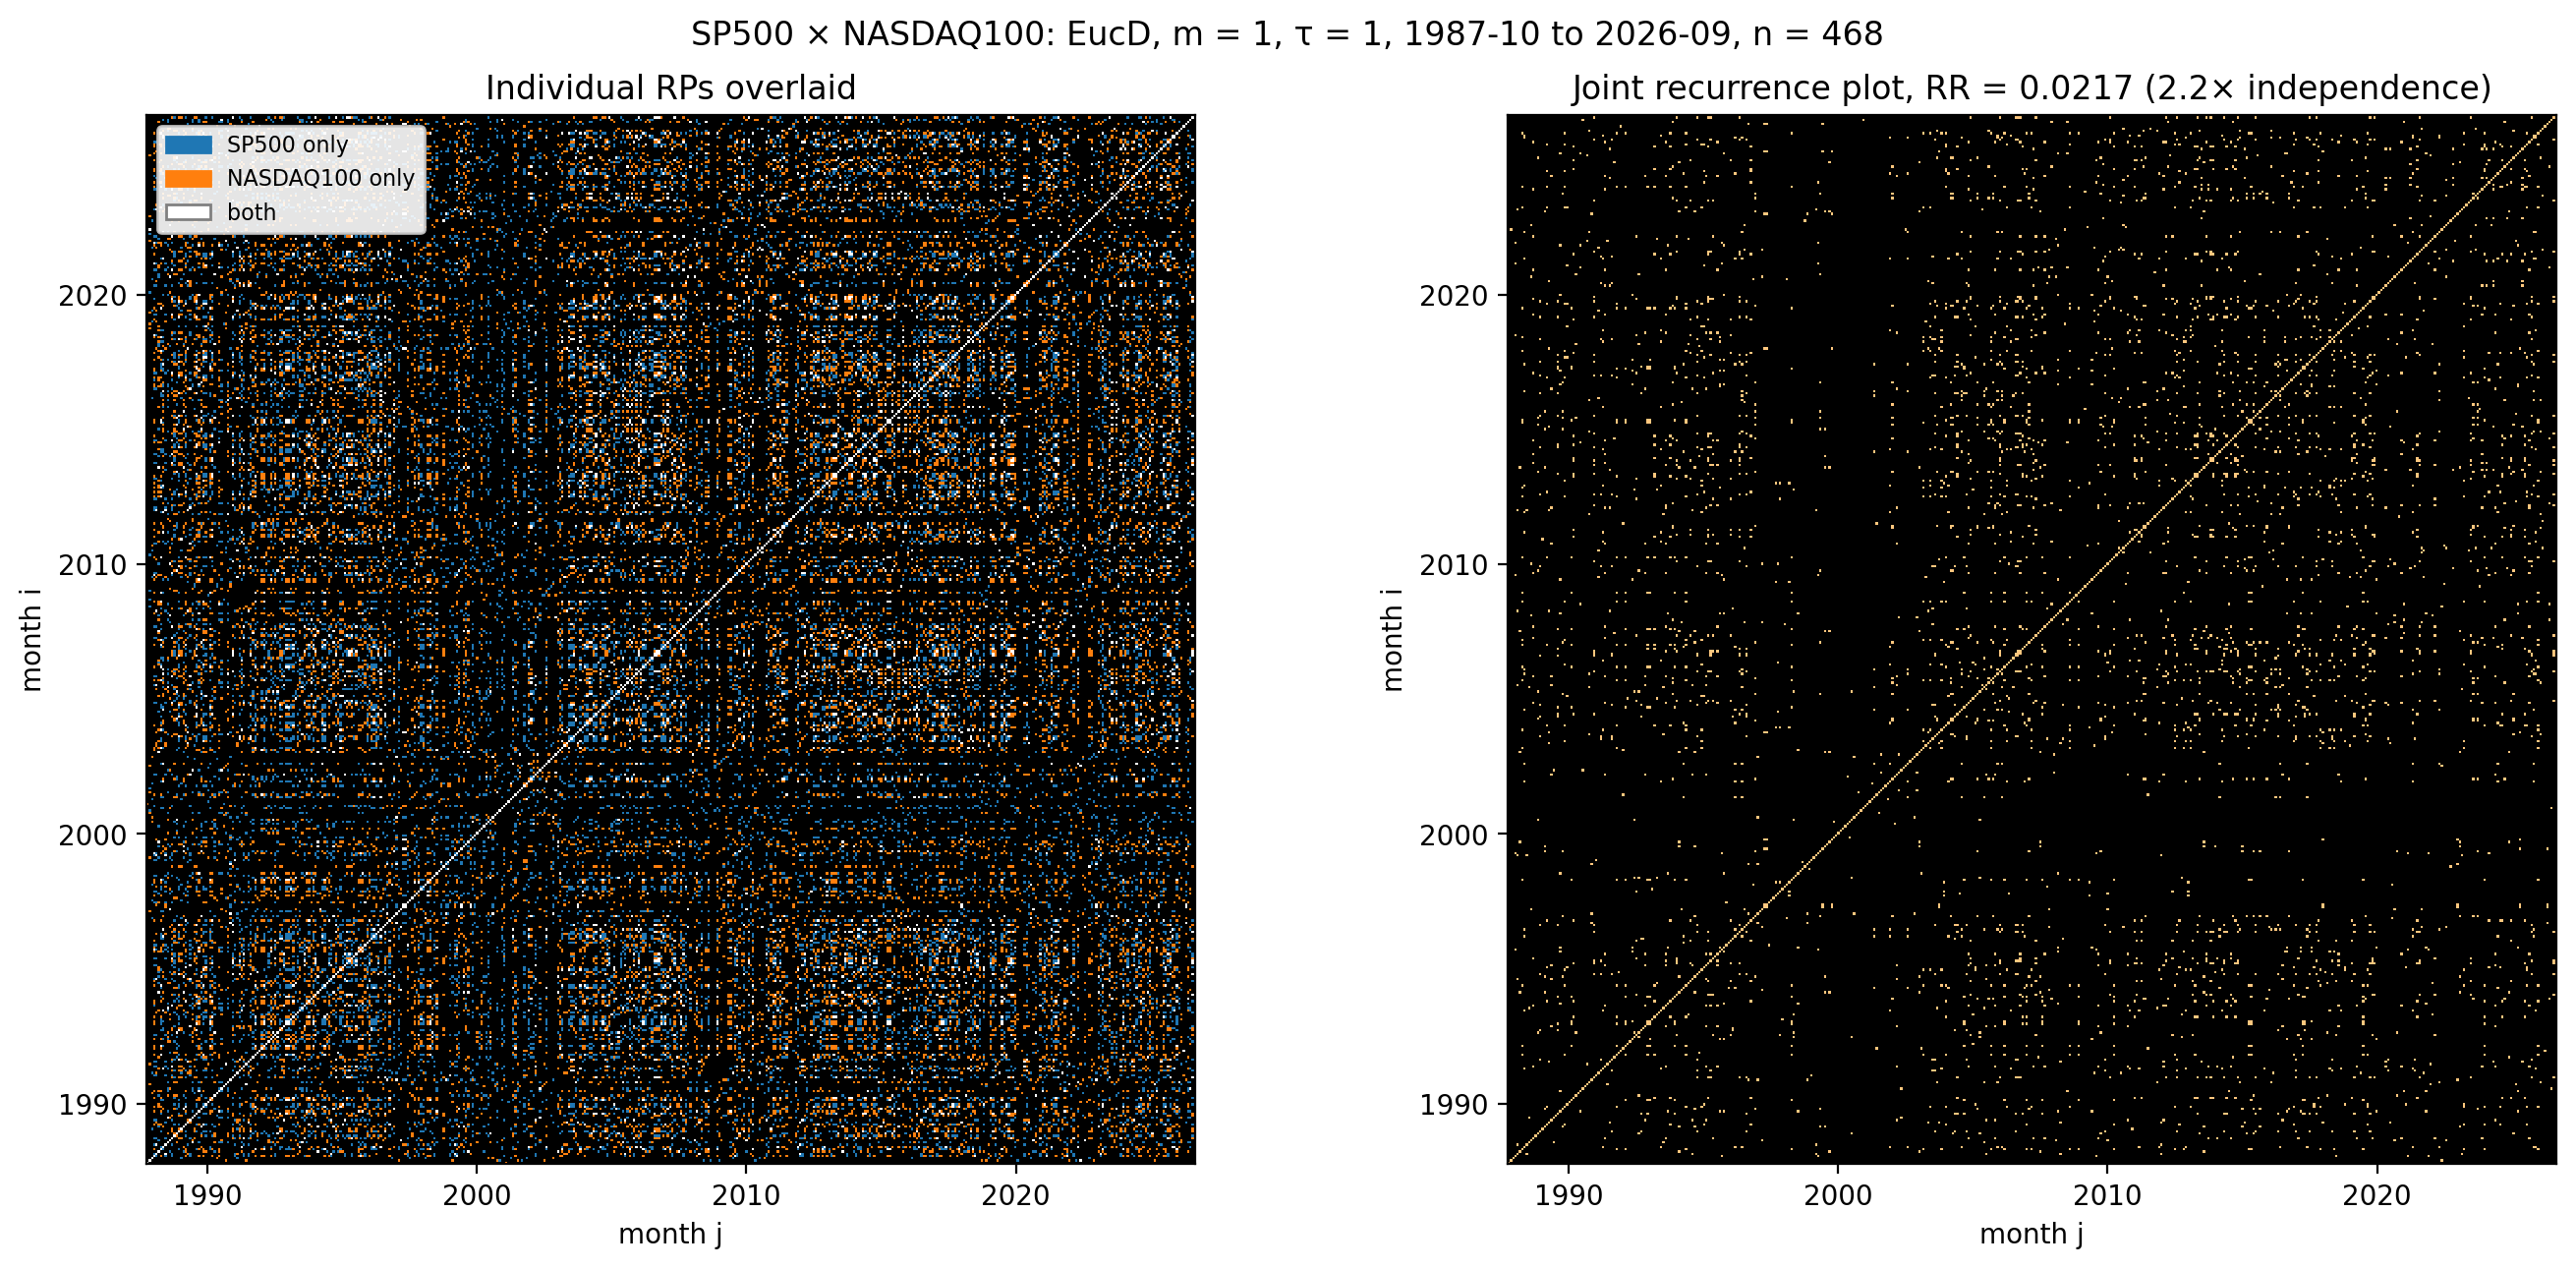

In [17]:
# S&P 500 x Nasdaq-100 JRP
jrps[("SP500", "NASDAQ100")] = plot_jrp("SP500", "NASDAQ100")

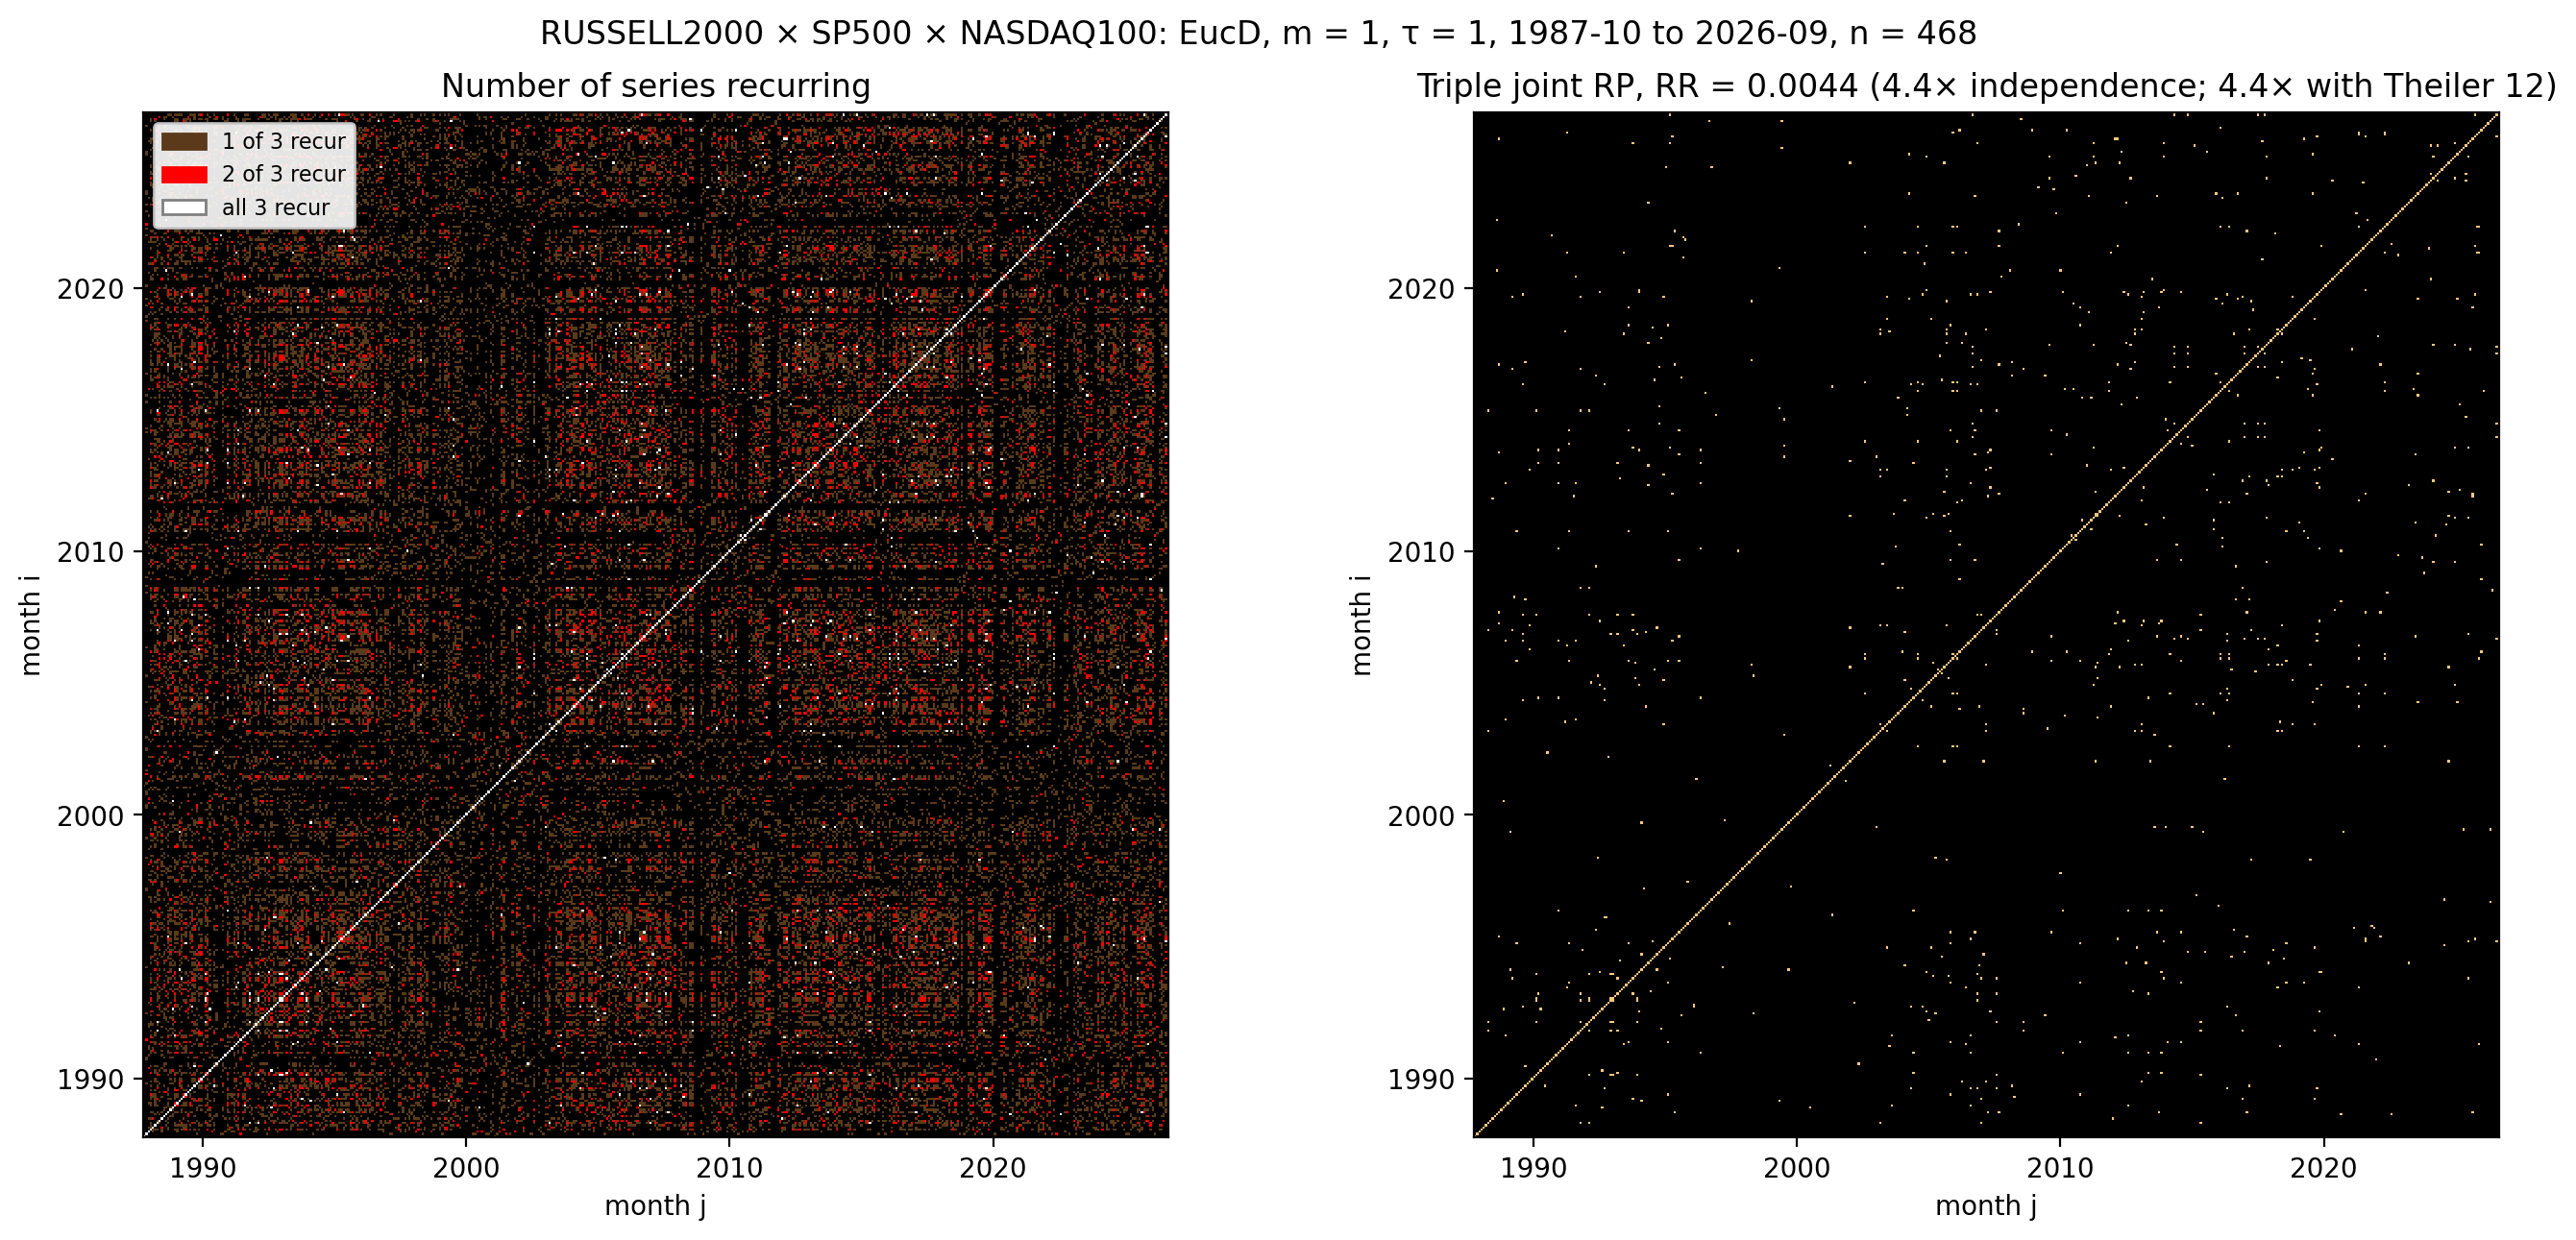

In [18]:
# Triple joint RP: months (i, j) are jointly recurrent only when ALL THREE series recur there:
# JR3 = R_RUSSELL2000 AND R_SP500 AND R_NASDAQ100. Each series keeps its own ε from cell 6.
COUNT_CMAP = ListedColormap(["black", "#5a3a1a", "red", "white"])  # 0, 1, 2, 3 series recurring

def plot_triple_jrp(a: str, b: str, c: str) -> np.ndarray:
    mats = [rps[a], rps[b], rps[c]]
    JR3 = np.logical_and.reduce(mats)
    key = f"{a} × {b} × {c}"
    stats, stats_theiler = independence.loc[key], independence_theiler.loc[key]
    dates = market.index[(M - 1) * TAU :]
    t0, t1 = mdates.date2num(dates[0]), mdates.date2num(dates[-1])
    extent = (t0, t1, t0, t1)

    fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
    count = sum(R.astype(int) for R in mats)  # how many of the three series recur at (i, j)
    ax[0].imshow(count, cmap=COUNT_CMAP, vmin=-0.5, vmax=3.5, origin="lower", interpolation="nearest", extent=extent)
    ax[0].legend(handles=[Patch(color=COUNT_CMAP(k), label=f"{k} of 3 recur") for k in (1, 2)]
                         + [Patch(facecolor="white", edgecolor="grey", label="all 3 recur")],
                 loc="upper left", fontsize=8, framealpha=0.9)
    ax[0].set_title("Number of series recurring")
    ax[1].imshow(JR3, cmap="copper", origin="lower", interpolation="nearest", extent=extent)
    ax[1].set_title(f"Triple joint RP, RR = {stats['joint RR']:.4f} "
                    f"({stats['ratio']:.1f}× independence; {stats_theiler['ratio']:.1f}× with Theiler {THEILER})")
    for x in ax:
        format_date_axes(x)
    fig.suptitle(f"{key}: EucD, m = {M}, τ = {TAU}, {dates[0]:%Y-%m} to {dates[-1]:%Y-%m}, n = {len(dates)}")
    fig.tight_layout()
    plt.show()
    return JR3

jrp3 = plot_triple_jrp("RUSSELL2000", "SP500", "NASDAQ100")


## 5. β-divergence: thresholded RPs only

Reuse the cleaned common monthly sample, embedding parameters `M`, `TAU`, and individual recurrence target `RR_TARGET` above. Each β below shows the same three individual, three pairwise joint, and one triple joint recurrence plots. No divergence heatmaps or recurrence overlays are shown.

**Positive inputs:** standard β-divergence is defined on nonnegative values; its β = 1 logarithm needs strictly positive values here. Signed log returns and their z-scores are unsuitable. Transform each log return $r_t$ (stored in percent) to its gross return $g_t=\exp(r_t/100)=P_t/P_{t-1}$. Losses remain below 1 and gains above 1; no absolute values or arbitrary shifts are used. This representation differs from the z-scored log returns in the Euclidean section, so differences from those plots are not due to β alone.

**Symmetry:** β-divergence is generally directional. Use the arithmetic mean of the forward and reverse divergences so that comparing times $(i,j)$ and $(j,i)$ gives the same result:

$$
S_\beta(x,y)=\frac{d_\beta(x\Vert y)+d_\beta(y\Vert x)}{2}
=\begin{cases}
\frac12(x-y)(\log x-\log y),&\beta=1,\\
\frac{(x-y)(x^{\beta-1}-y^{\beta-1})}{2(\beta-1)},&\beta>1.
\end{cases}
$$

Sum these scalar divergences over embedded coordinates. This is a symmetric divergence, not a metric. For each series and β, select ε from the same upper-triangle quantile as before, then set $R_{ij}=1\{S_{\beta,ij}\leq\varepsilon\}$. Joint plots intersect the corresponding individual RPs without choosing another threshold. Titles report actual off-diagonal recurrence rates; ties may exceed the target.

β = 1 is the generalized KL case. Larger β weights differences at higher gross-return levels more strongly. Thresholds have divergence units and should not be compared numerically with Euclidean ε.

Definition: [Févotte & Idier, *Algorithms for nonnegative matrix factorization with the β-divergence*, §2.1, Eq. (5)](https://arxiv.org/abs/1010.1763). The symmetric average and gross-return representation are explicit choices for these RPs.


In [19]:
def symmetric_beta_matrix(states: np.ndarray, beta: float) -> np.ndarray:
    """Coordinate-summed mean of forward and reverse β-divergences."""
    states = np.asarray(states, dtype=float)
    if states.ndim != 2 or not np.isfinite(states).all() or np.any(states <= 0):
        raise ValueError("β-divergence states must be a finite, strictly positive 2D array")
    if not np.isfinite(beta) or beta < 1:
        raise ValueError("This implementation supports β >= 1")
    transformed = np.log(states) if beta == 1 else states ** (beta - 1) / (beta - 1)
    divergence = 0.5 * (
        (states[:, None, :] - states[None, :, :])
        * (transformed[:, None, :] - transformed[None, :, :])
    ).sum(axis=-1)
    if not np.isfinite(divergence).all():
        raise ValueError("β-divergence overflow; check the input scale")
    return divergence


def beta_recurrence(series: pd.Series, beta: float, m: int, tau: int, rr: float):
    gross = np.exp(series.to_numpy(dtype=float) / 100)
    if m < 1 or tau < 1 or len(gross) - (m - 1) * tau < 2:
        raise ValueError("Embedding requires positive m, tau and at least two states")
    states = embed(gross, m, tau)
    divergence = symmetric_beta_matrix(states, beta)
    upper = np.triu_indices(len(states), k=1)
    eps = float(np.quantile(divergence[upper], rr))
    dates = series.index[(m - 1) * tau :]
    return divergence <= eps, eps, dates


def plot_beta_rps(beta: float):
    individual, thresholds = {}, {}
    for col in series_cols:
        individual[col], thresholds[col], dates = beta_recurrence(
            market[col], beta, M, TAU, RR_TARGET,
        )
    upper = np.triu_indices(len(dates), k=1)
    pairwise = {
        (a, b): individual[a] & individual[b]
        for a, b in combinations(series_cols, 2)
    }
    triple = np.logical_and.reduce([individual[col] for col in series_cols])
    t0, t1 = mdates.date2num(dates[0]), mdates.date2num(dates[-1])
    extent = (t0, t1, t0, t1)
    period = f"{dates[0]:%Y-%m} to {dates[-1]:%Y-%m}, n = {len(dates)}"

    def draw_group(items, heading):
        fig, axes = plt.subplots(
            1, len(items), figsize=(5 * len(items), 6), squeeze=False, layout="constrained",
        )
        for ax, (label, matrix, eps) in zip(axes[0], items):
            ax.imshow(
                matrix, cmap="copper", vmin=0, vmax=1, origin="lower",
                interpolation="nearest", extent=extent,
            )
            threshold_label = "" if eps is None else f", ε = {eps:.3g}"
            ax.set_title(f"{label}\nRR = {matrix[upper].mean():.4f}{threshold_label}")
            format_date_axes(ax)
        fig.suptitle(
            f"Symmetric β = {beta:g}: {heading}\n"
            f"Gross returns, m = {M}, τ = {TAU}; {period}"
        )
        plt.show()

    draw_group(
        [(col, individual[col], thresholds[col]) for col in series_cols],
        "Individual thresholded RPs",
    )
    draw_group(
        [(f"{a} × {b}", matrix, None) for (a, b), matrix in pairwise.items()],
        "Pairwise joint thresholded RPs",
    )
    draw_group(
        [(" × ".join(series_cols), triple, None)],
        "Triple joint thresholded RP",
    )
    return {
        "individual": individual, "thresholds": thresholds,
        "pairwise": pairwise, "triple": triple, "dates": dates,
    }


beta_results = {}


### β = 1


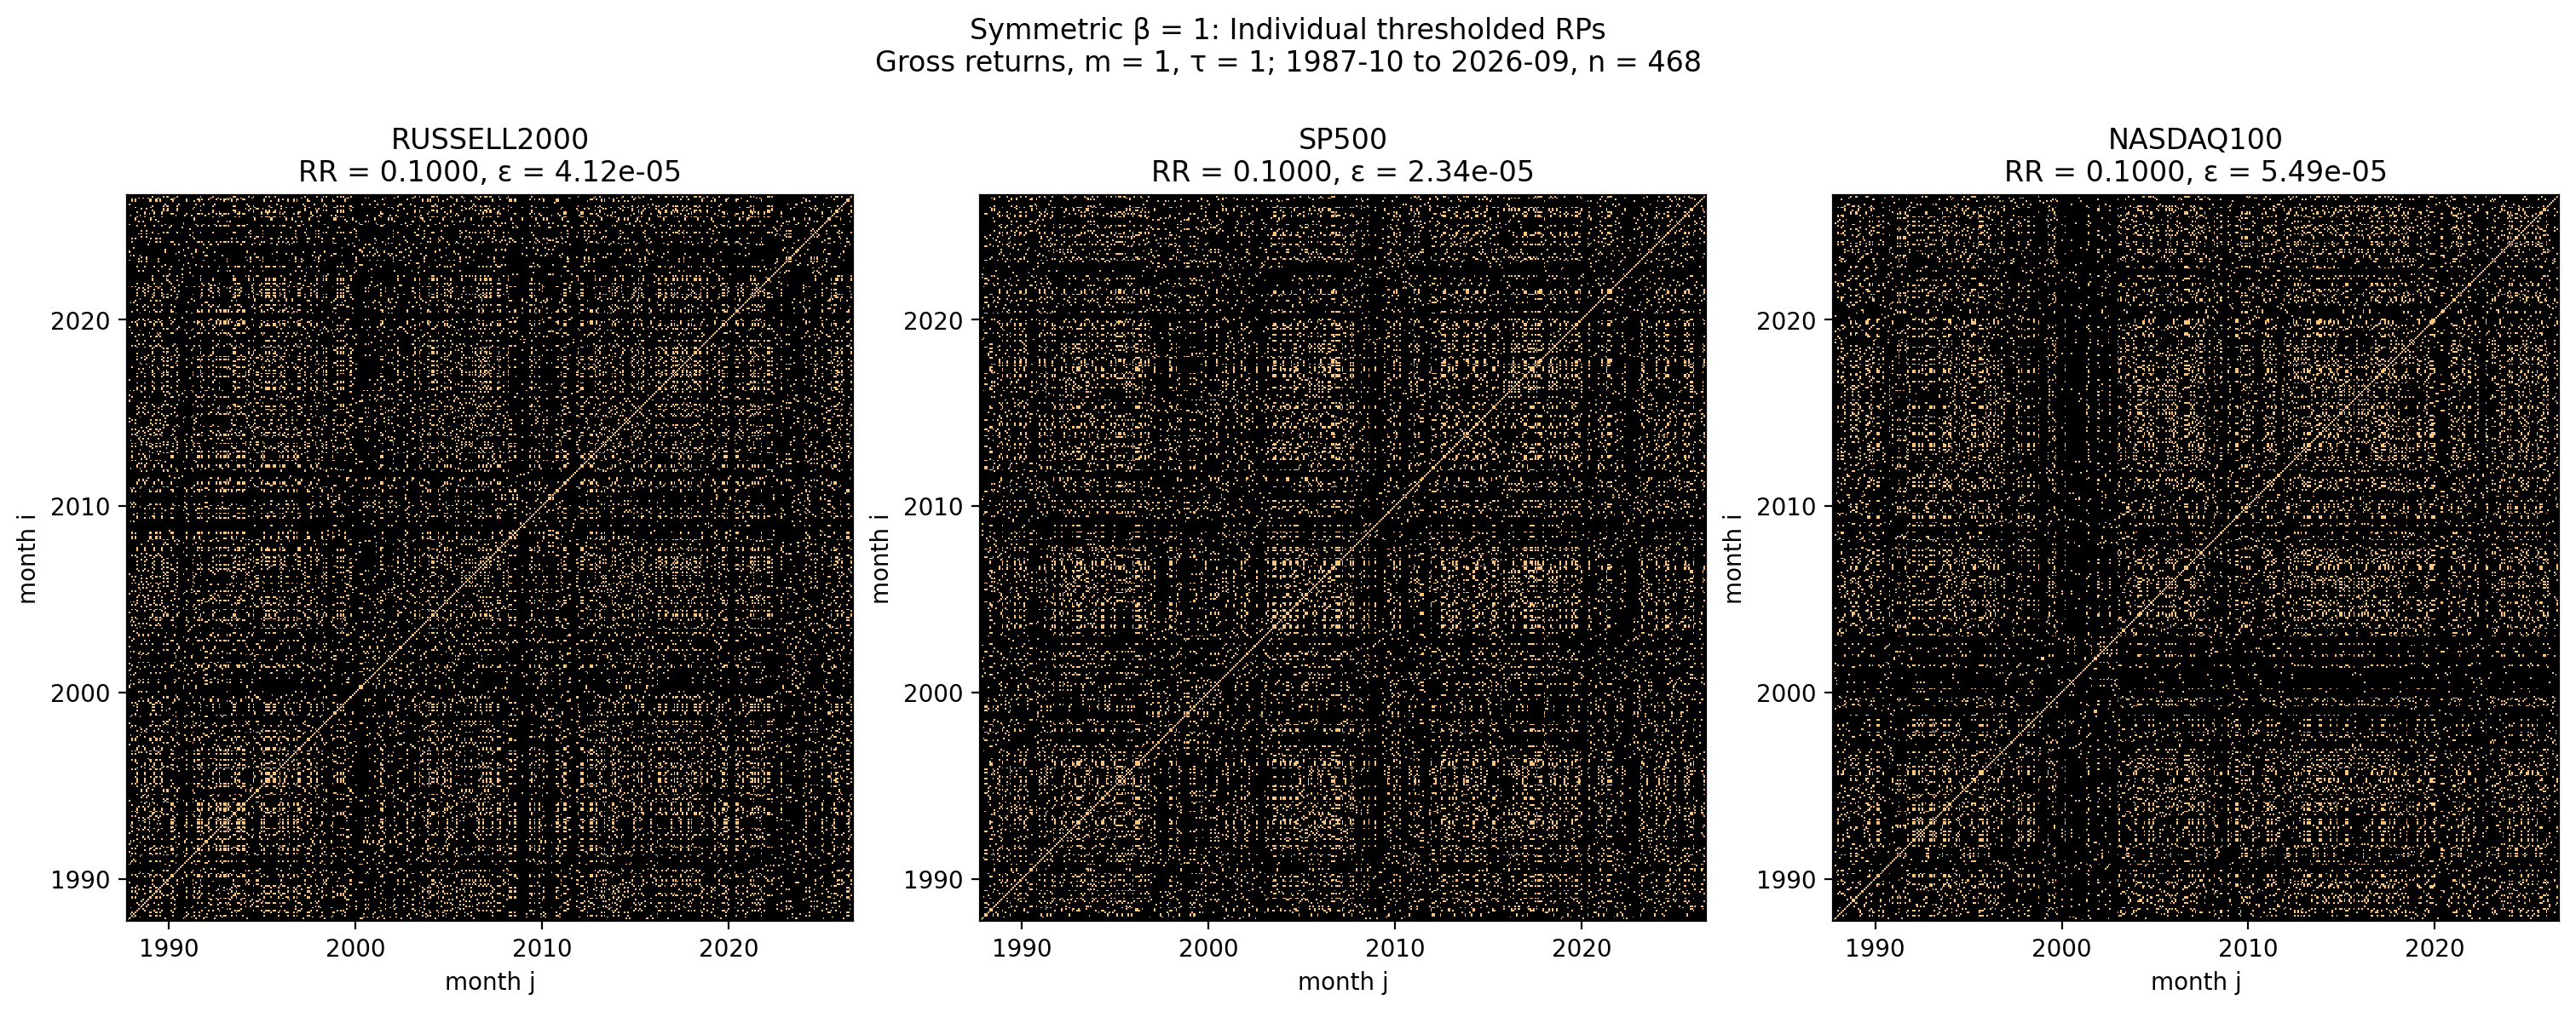

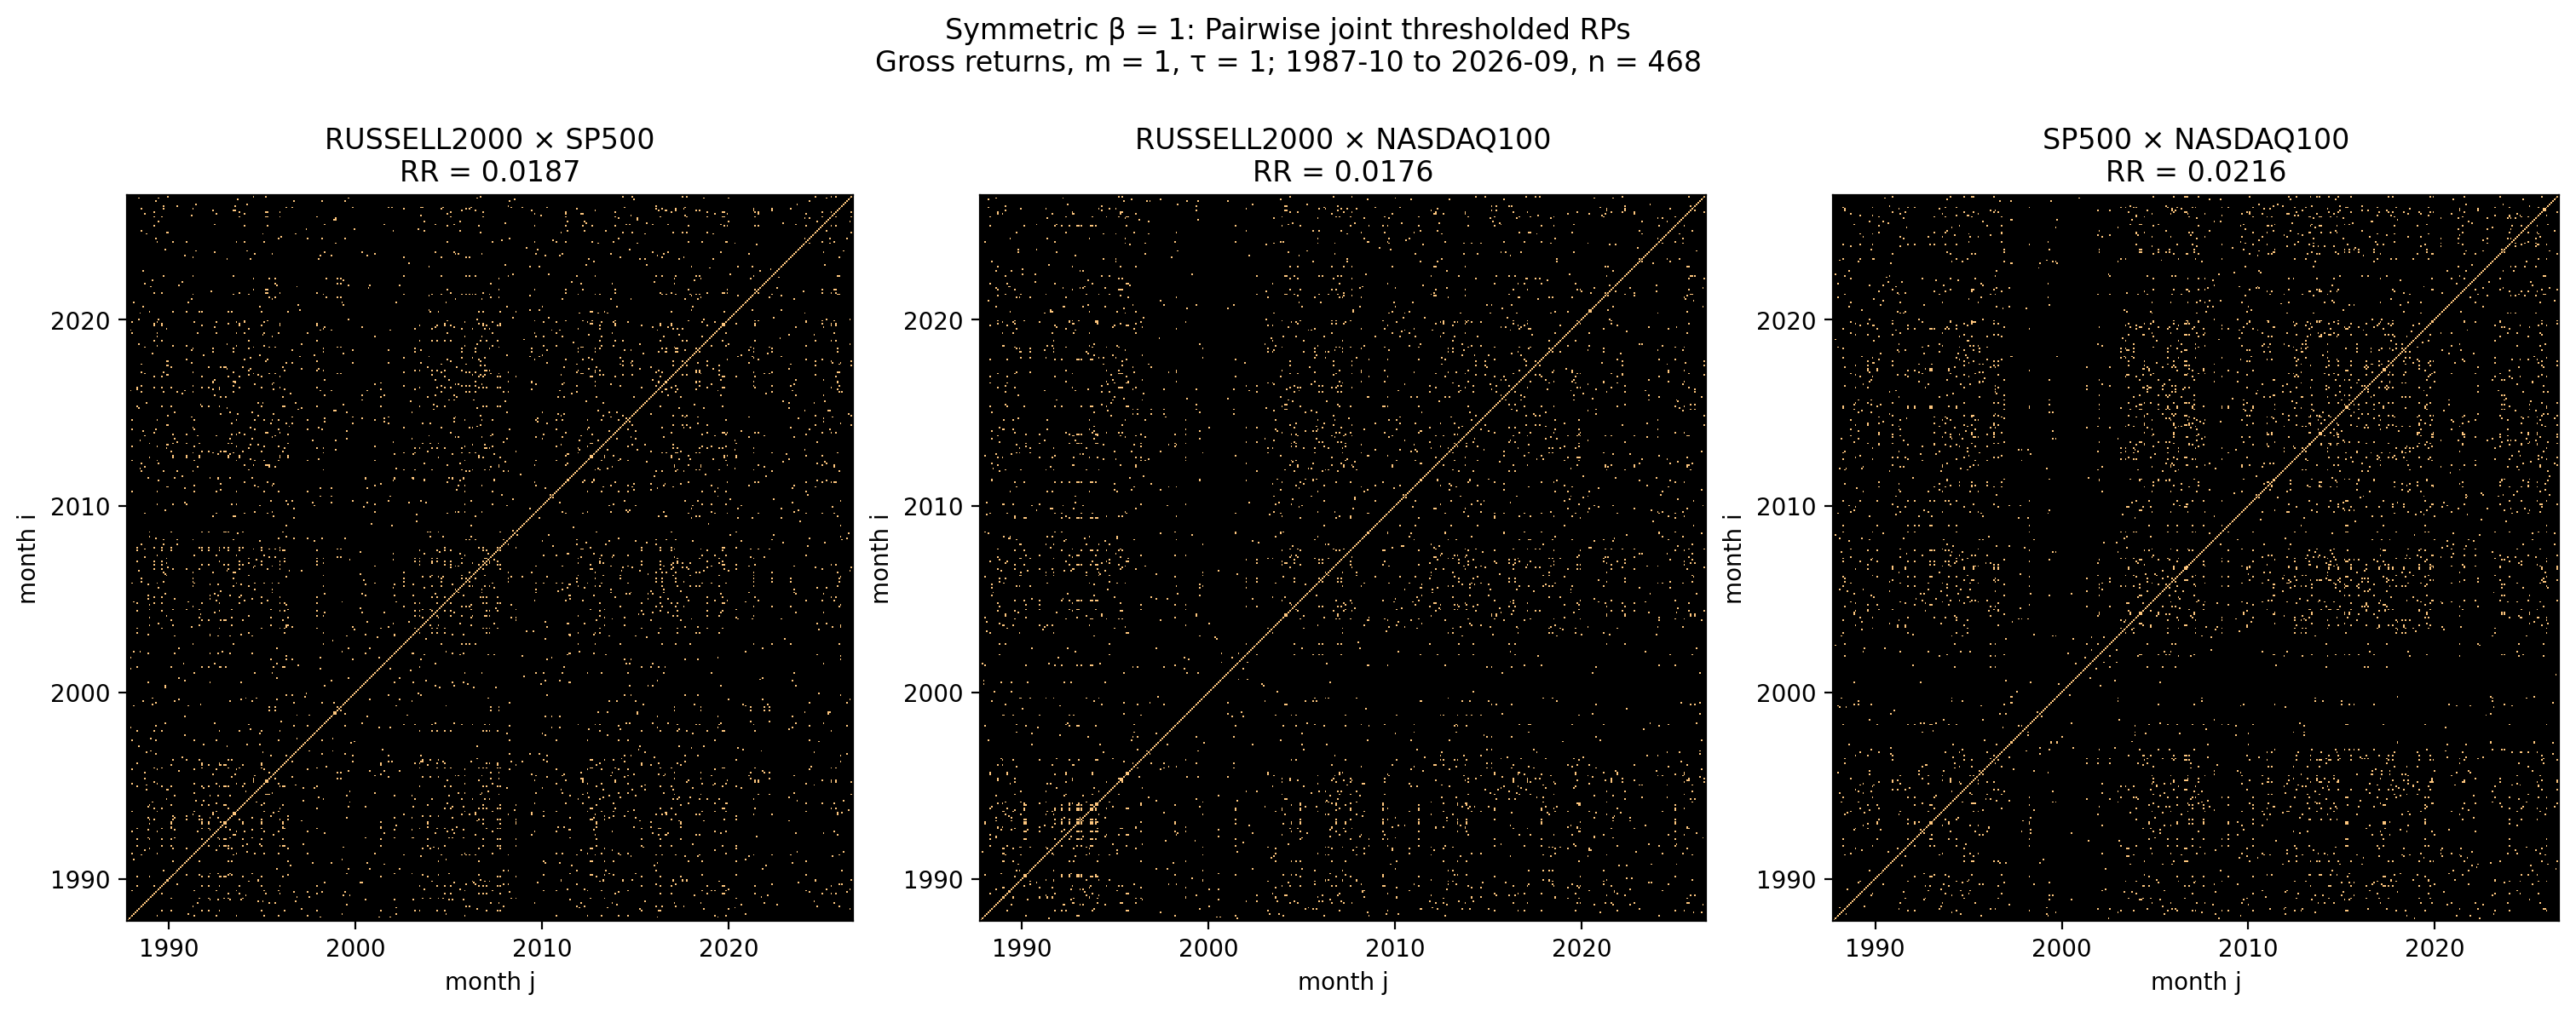

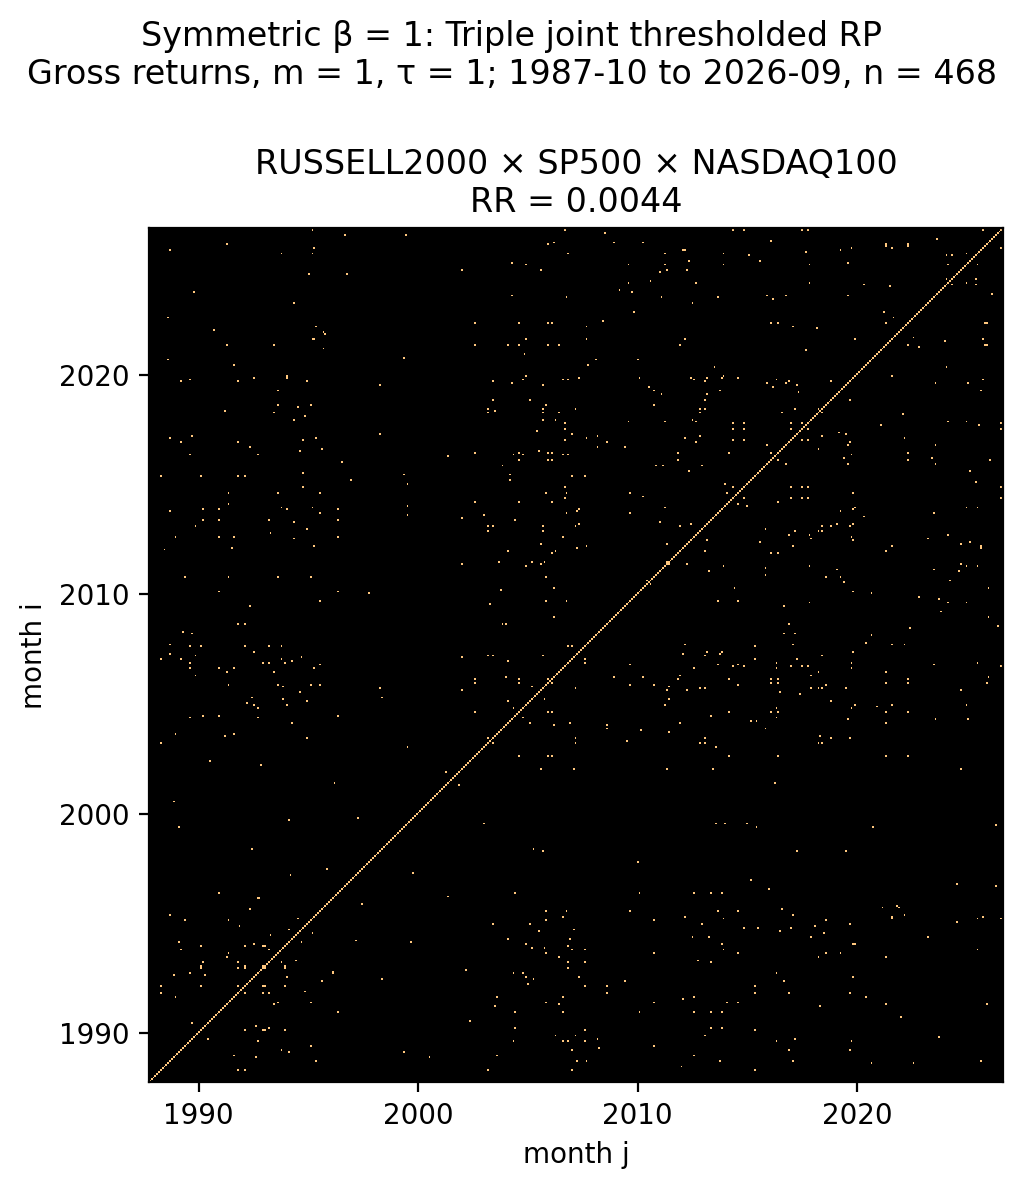

In [20]:
beta_results[1] = plot_beta_rps(1)


### β = 3


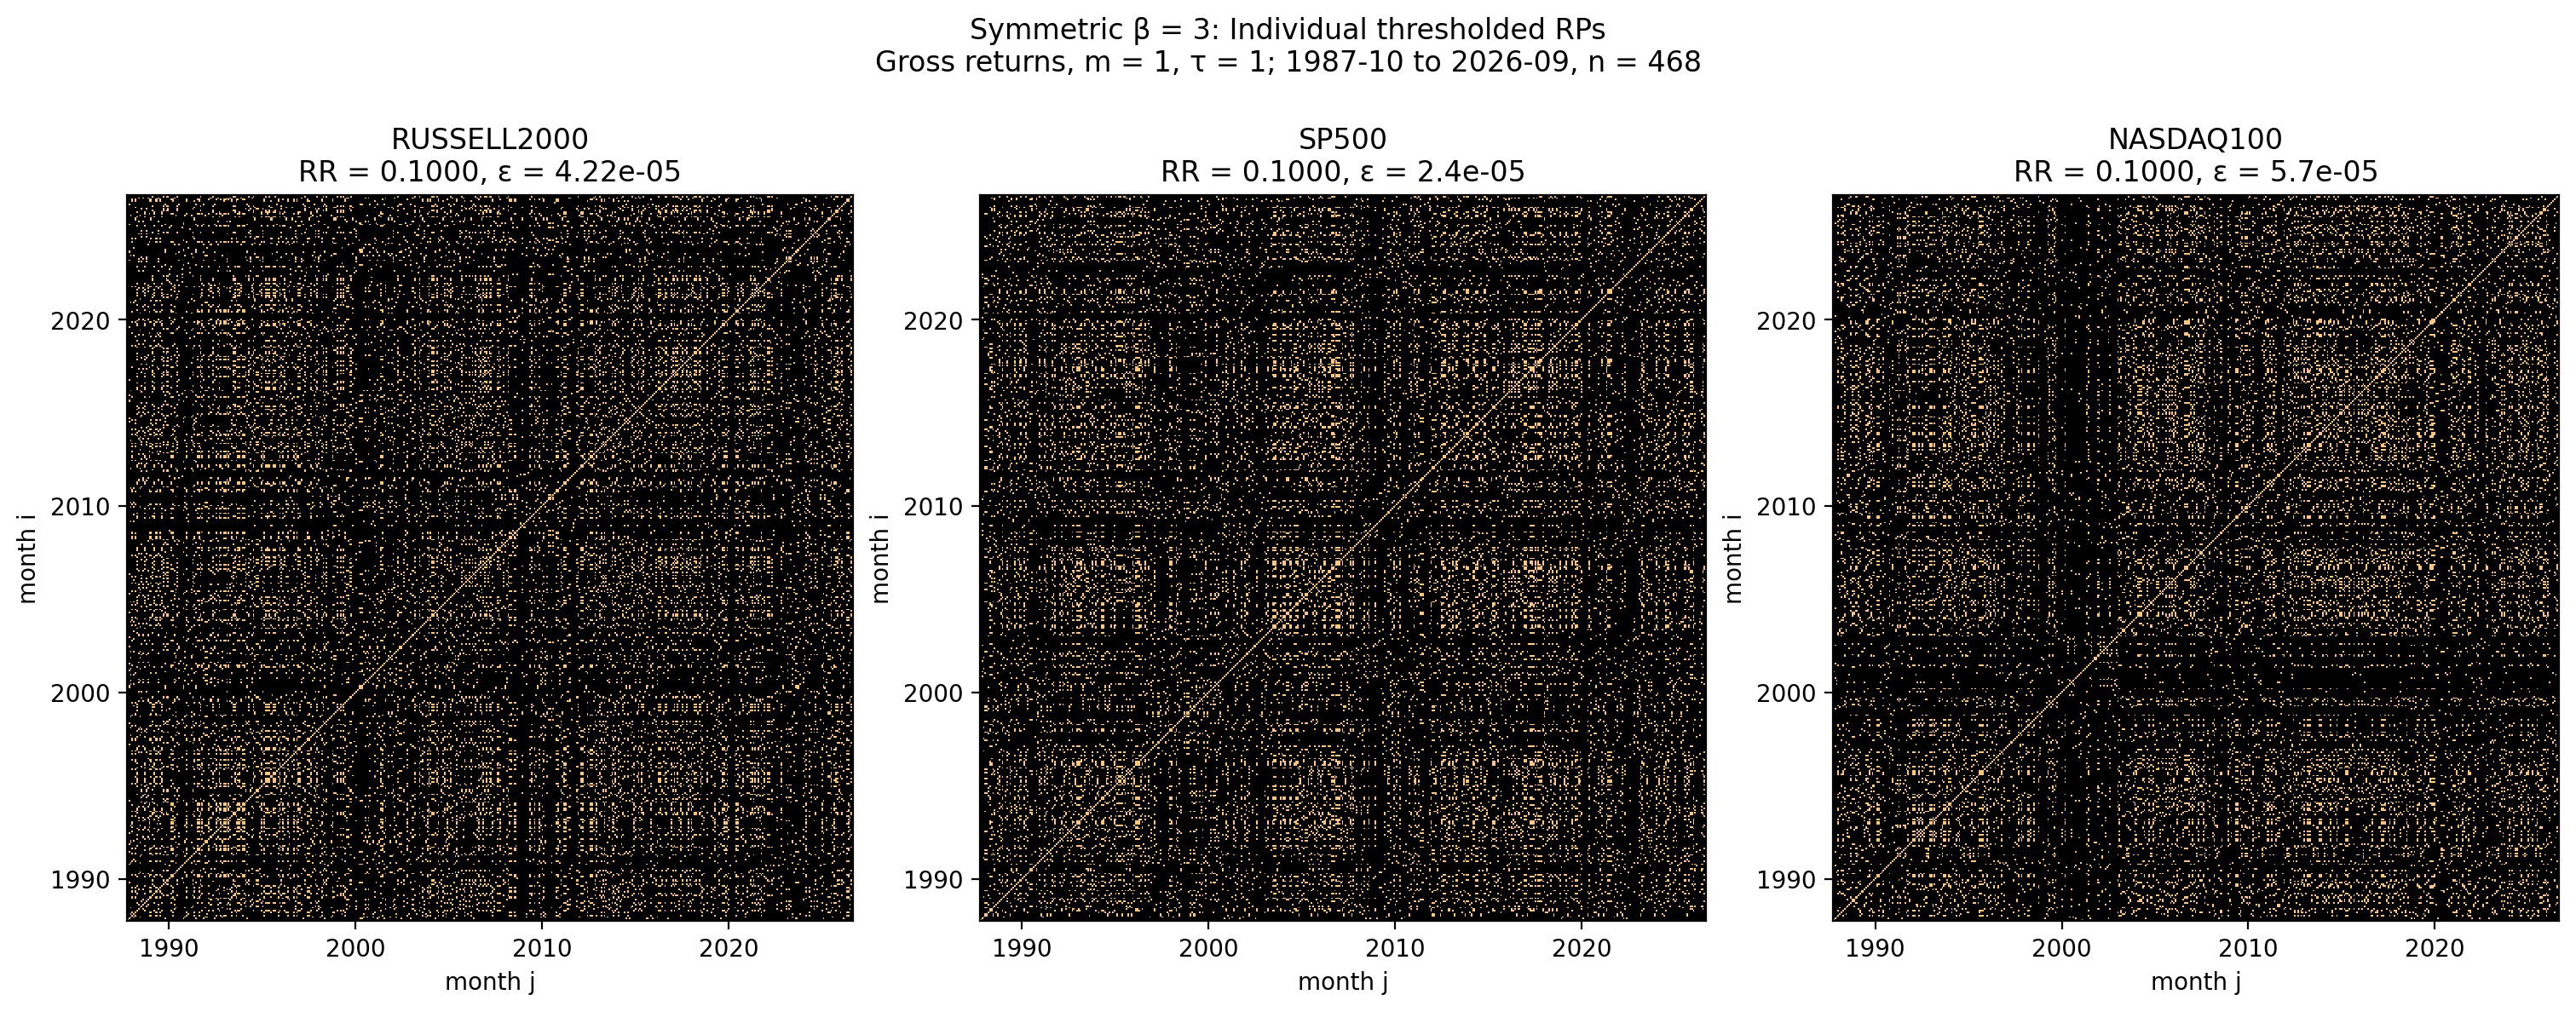

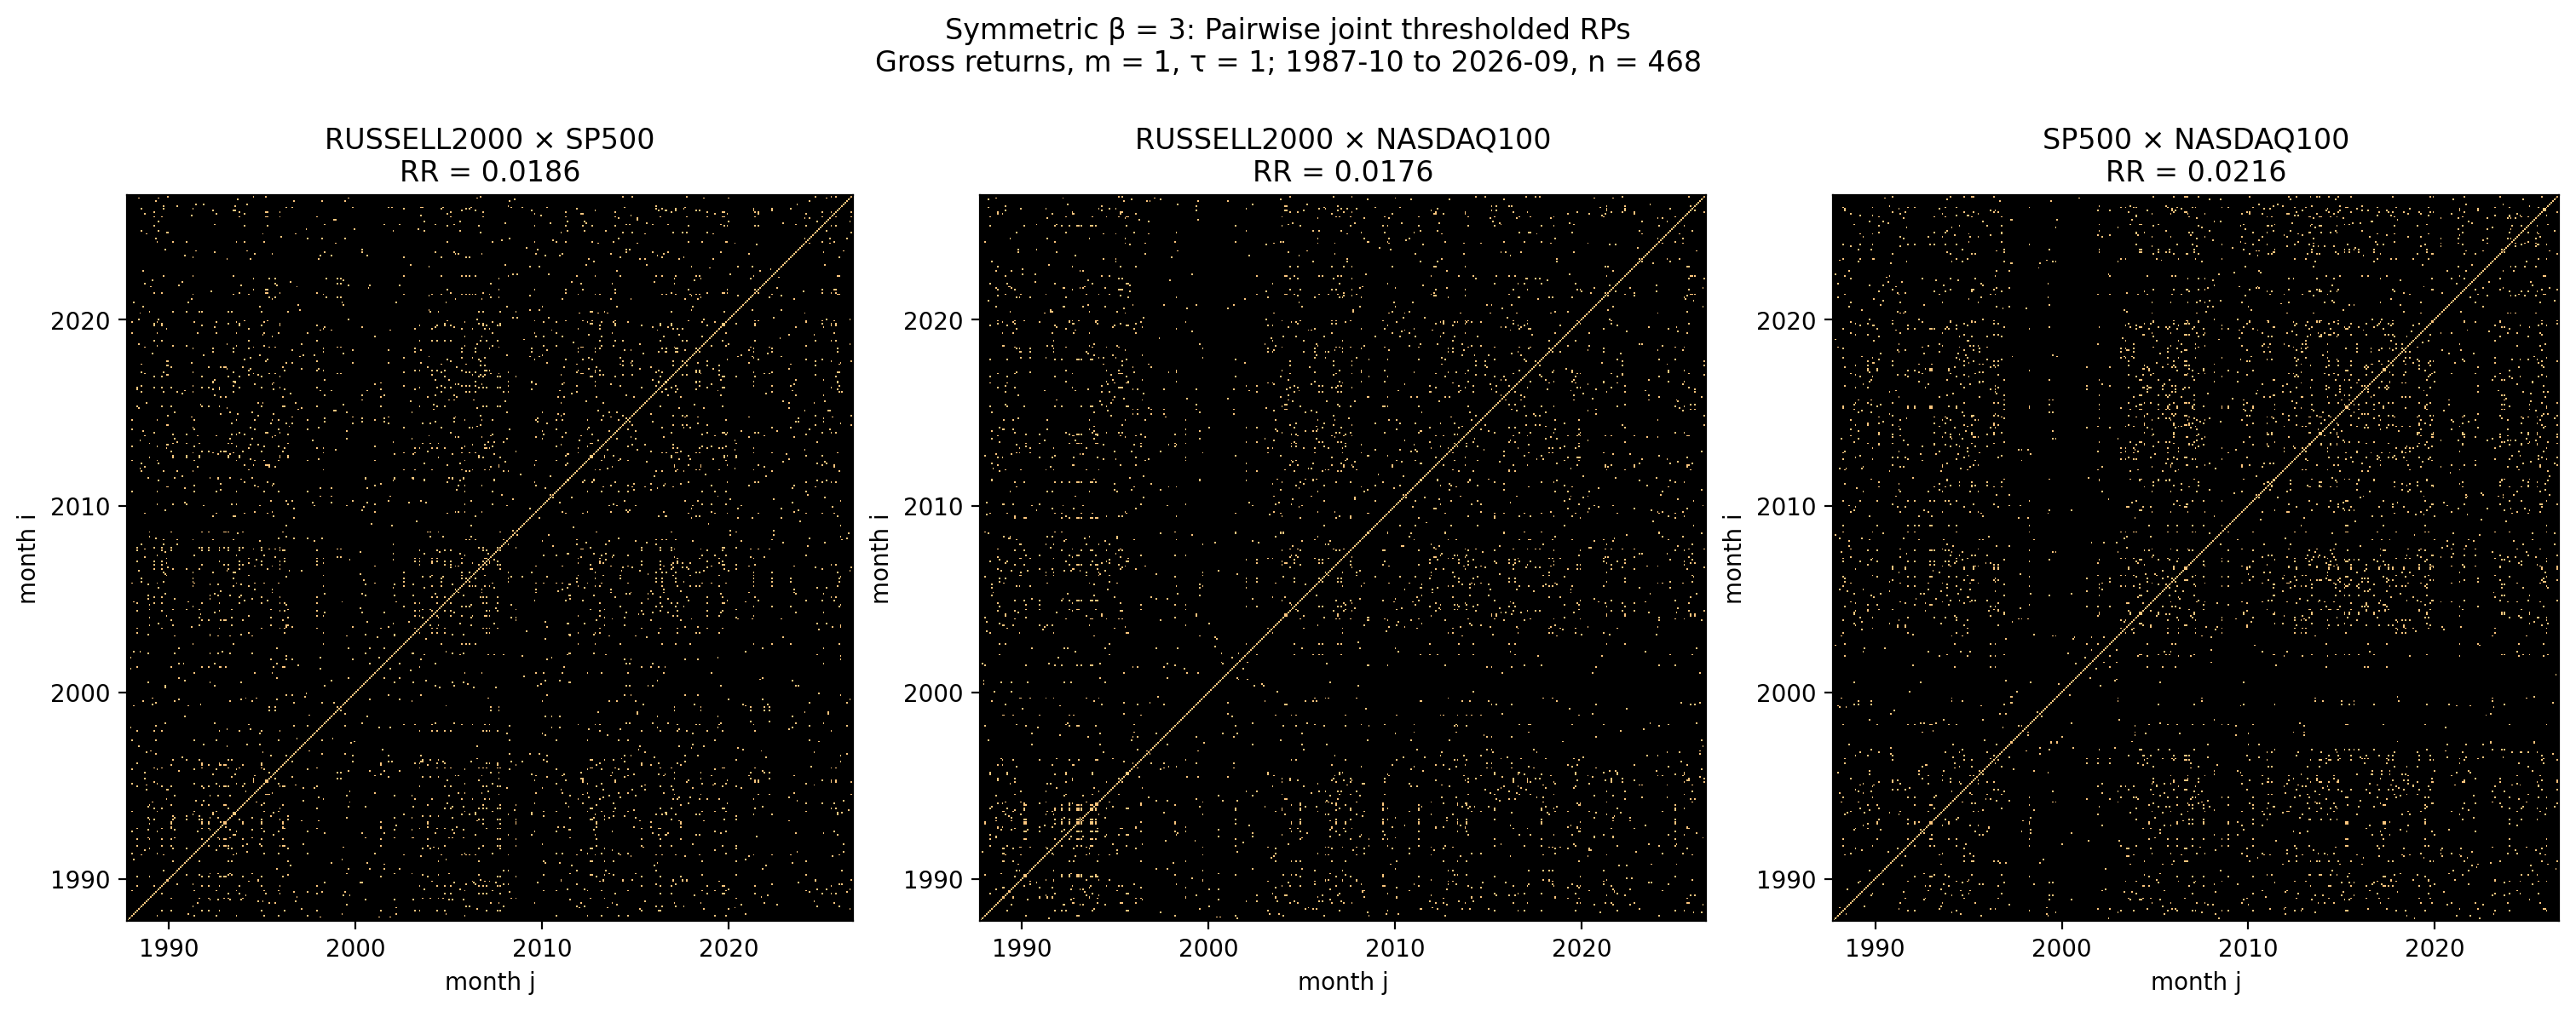

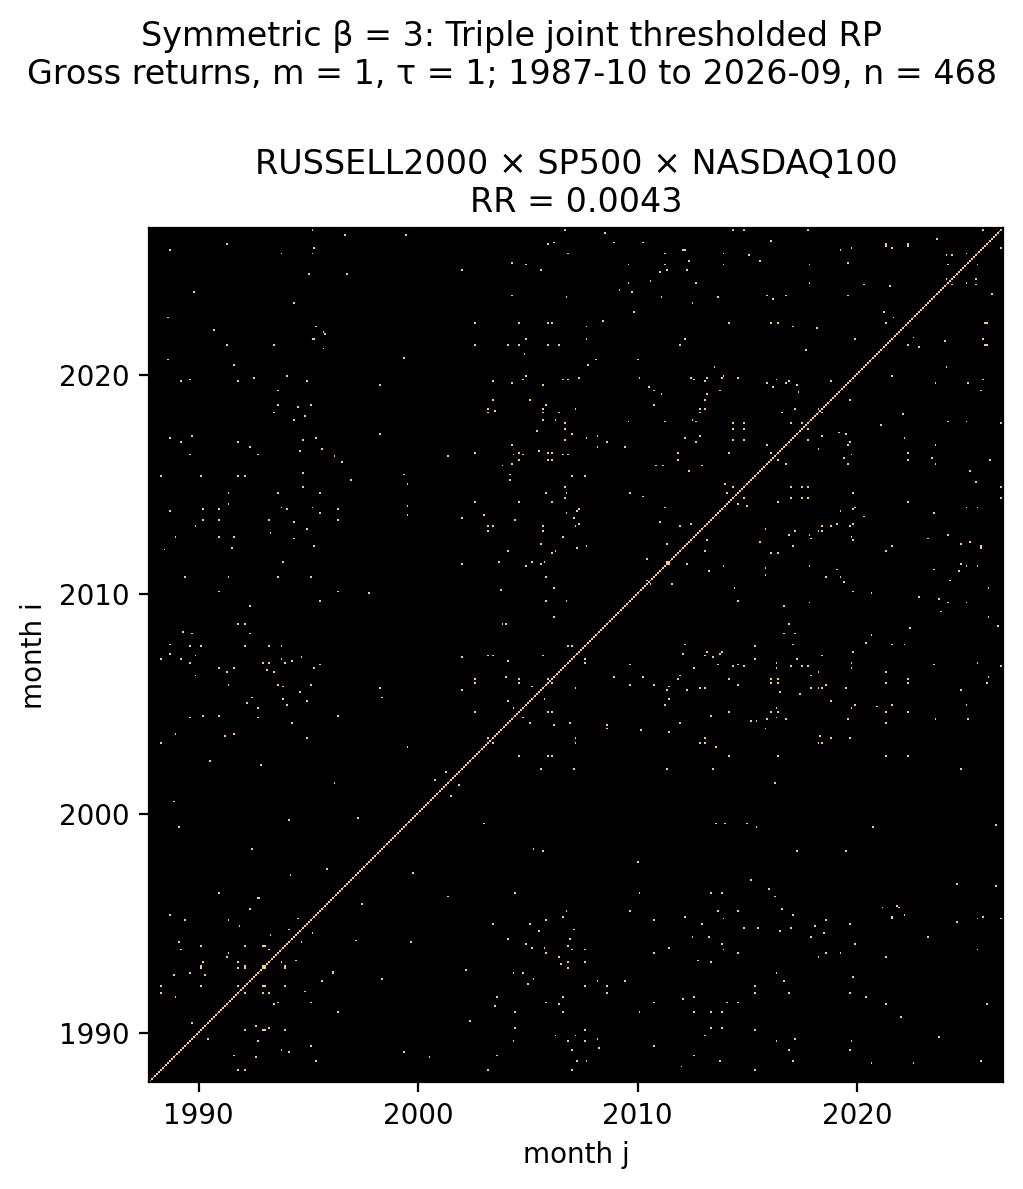

In [21]:
beta_results[3] = plot_beta_rps(3)


### β = 7


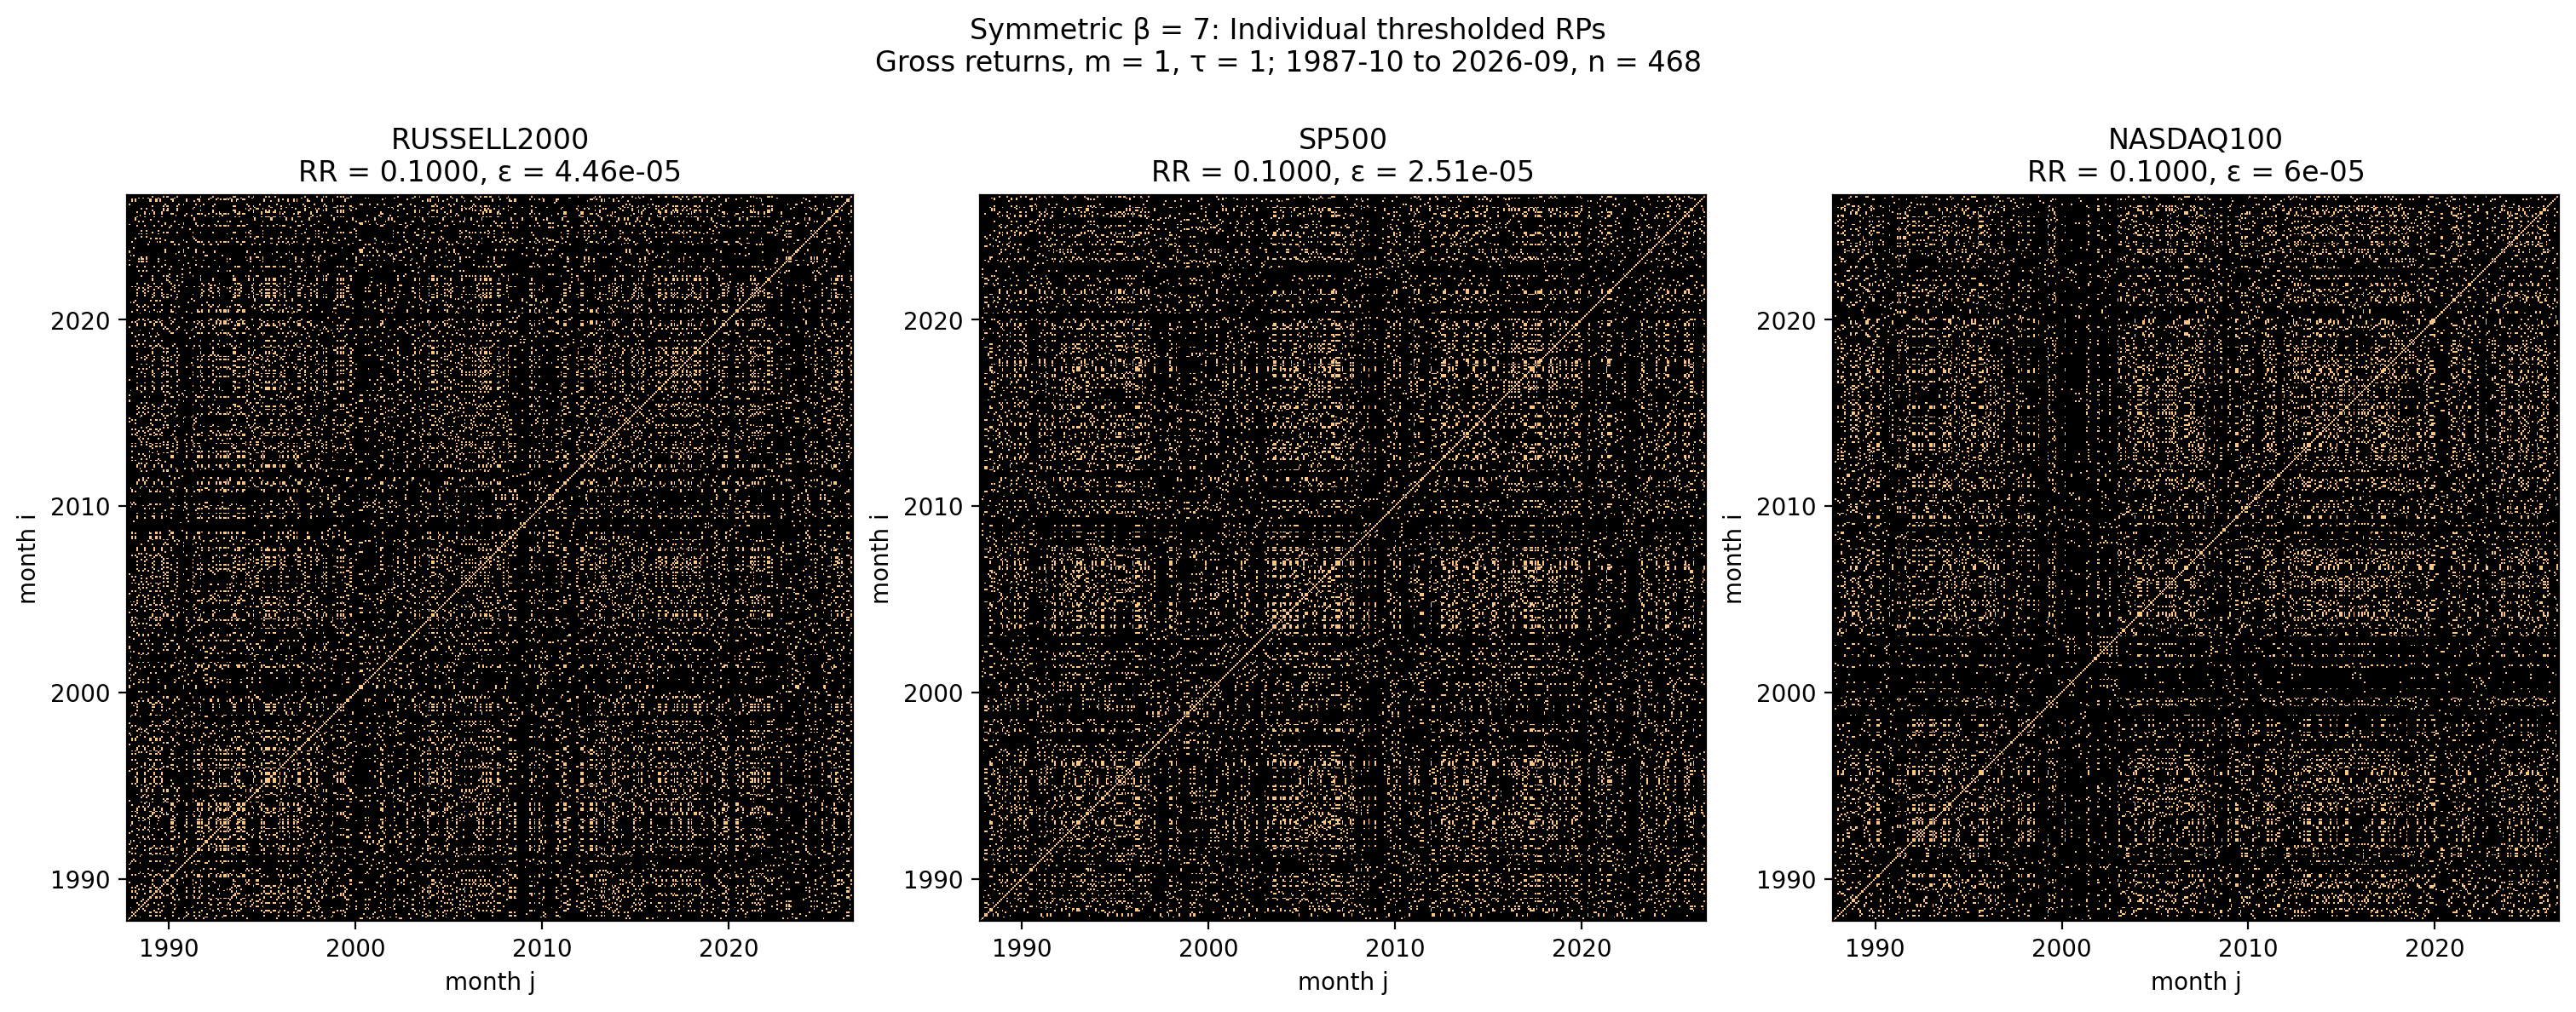

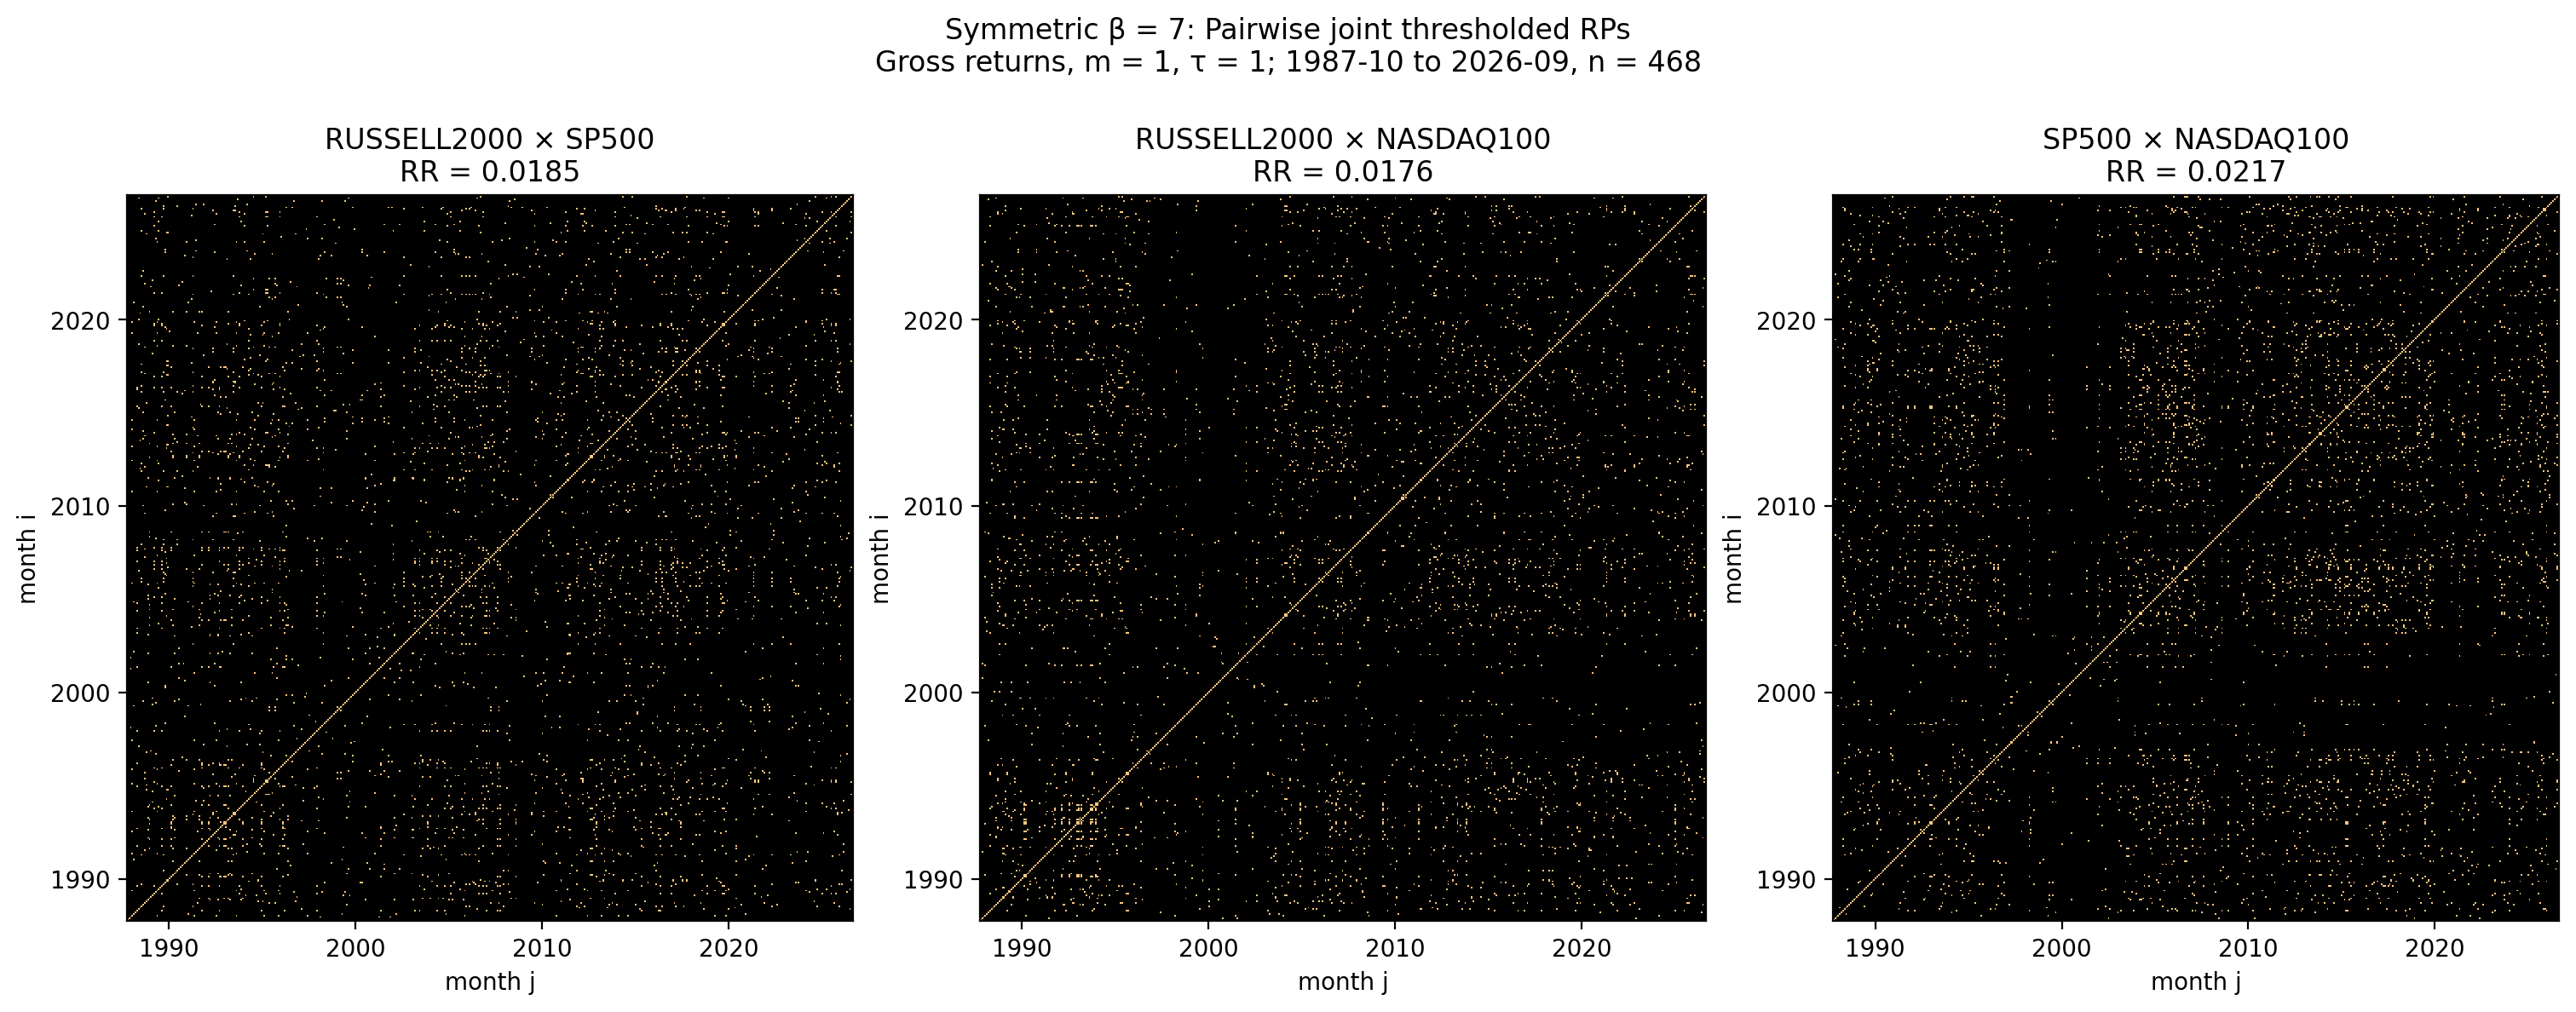

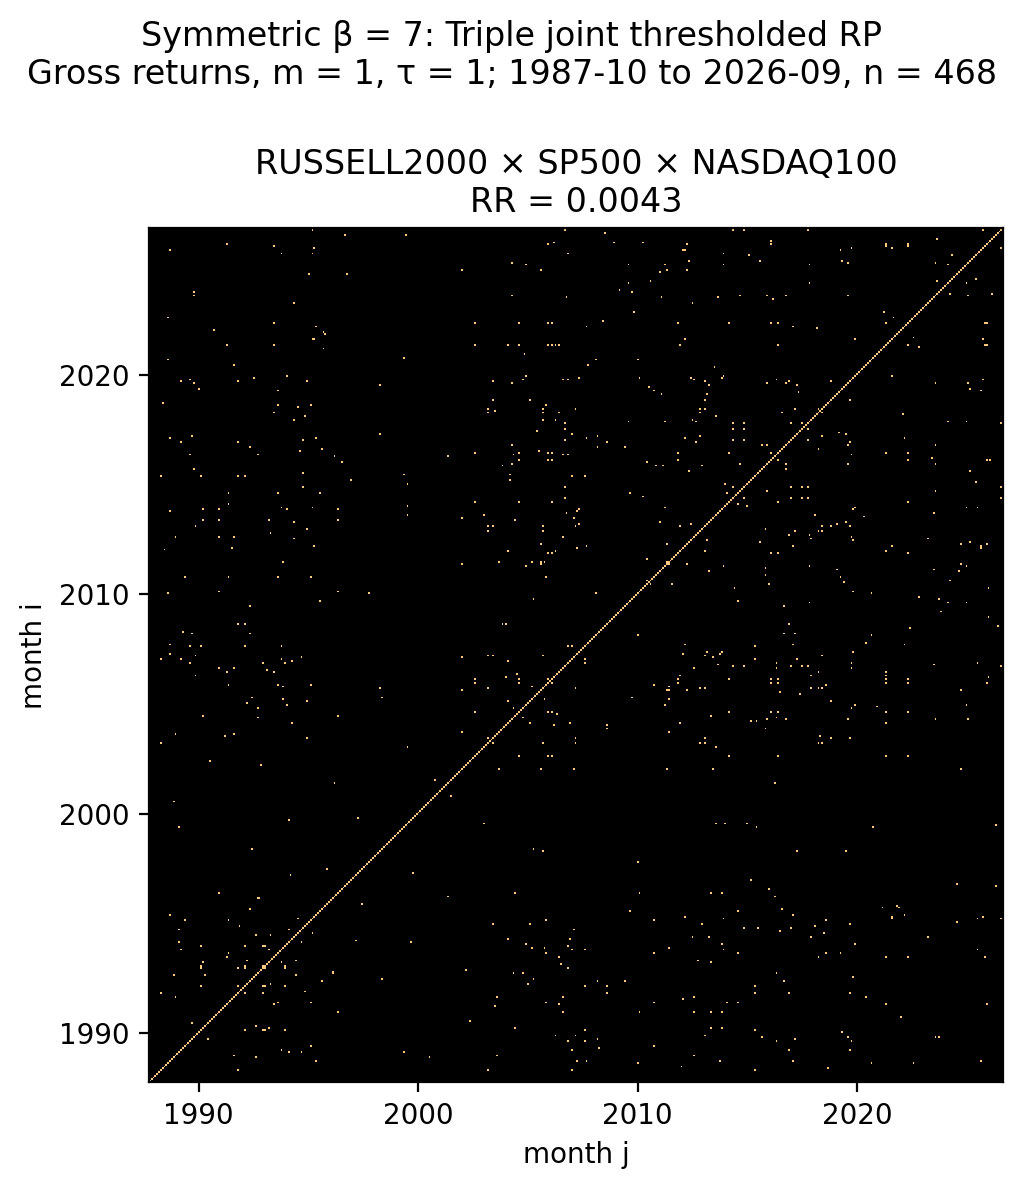

In [22]:
beta_results[7] = plot_beta_rps(7)